## Setup

In [ ]:
!pip install -q transformers
!pip install -q sentencepiece
!pip install -q jiwer
!pip install -q datasets
!pip install -q evaluate
!pip install -q -U accelerate

!pip install -q matplotlib
!pip install -q protobuf==3.20.1
!pip install -q tensorboard

In [ ]:
%env CUDA_LAUNCH_BLOCKING=1


## Imports

In [1]:
import os
import torch
import evaluate
import numpy as np
import pandas as pd
import glob as glob
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from PIL import Image
from zipfile import ZipFile
from tqdm.notebook import tqdm
from dataclasses import dataclass
from torch.utils.data import Dataset
from urllib.request import urlretrieve
# from transformers import (
#     VisionEncoderDecoderModel, 
#     TrOCRProcessor,
#     AutoTokenizer,
#     ViTFeatureExtractor,
#     BertTokenizer,
#     Seq2SeqTrainer,
#     Seq2SeqTrainingArguments,
#     default_data_collator
# )

from transformers import VisionEncoderDecoderModel, TrOCRProcessor,TrOCRConfig, ViTConfig, BertTokenizer, Seq2SeqTrainer, Seq2SeqTrainingArguments, VisionEncoderDecoderConfig,XLMRobertaTokenizer
block_plot = False
plt.rcParams['figure.figsize'] = (12, 9)

In [ ]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

In [2]:
# Then clean the cache
torch.cuda.empty_cache()
    # then collect the garbage


In [ ]:
bold = f"\033[1m"
reset = f"\033[0m"

In [3]:
def seed_everything(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Download and Extract the Dataset

In [ ]:
# def download_and_unzip(url, save_path):
#     print(f"Downloading and extracting assets....", end="")

#     # Downloading zip file using urllib package.
#     urlretrieve(url, save_path)

#     try:
#         # Extracting zip file using the zipfile package.
#         with ZipFile(save_path) as z:
#             # Extract ZIP file contents in the same directory.
#             z.extractall(os.path.split(save_path)[0])

#         print("Done")

#     except Exception as e:
#         print("\nInvalid file.", e)

In [ ]:
# URL = r"https://www.dropbox.com/scl/fi/vyvr7jbdvu8o174mbqgde/scut_data.zip?rlkey=fs8axkpxunwu6if9a2su71kxs&dl=1"
# asset_zip_path = os.path.join(os.getcwd(), "scut_data.zip")
# # Download if asset ZIP does not exist.
# if not os.path.exists(asset_zip_path):
#     download_and_unzip(URL, asset_zip_path)

## Training and Dataset Configurations

In [61]:
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:    int = 8
    EPOCHS:        int = 10
    LEARNING_RATE: float = 0.00005

@dataclass(frozen=True)
class DatasetConfig:
    DATA_ROOT:     str = 'dataset'

@dataclass(frozen=True)
class ModelConfig:
    # ENCODER_NAME: str = 'facebook/vit-mae-base'  # Change to your vision encoder if needed
    # DECODER_NAME: str = 'bert-base-uncased'      # Change to your custom Khmer BERT model if available
    # VOCAB_FILE: str = '/home/EmHengly/khmer_trocr/pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt'
    
    MODEL_NAME: str = 'microsoft/trocr-small-printed'
    # MODEL_NAME: str = "kkatiz/thai-trocr-thaigov-v2"
    
    
    # VOCAB_FILE: str = '/home/EmHengly/khmer_trocr/pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt'

## The SCUT Dataset

The SCUT dataset that we are using contains a total of 7703 images. Out of these 6052 are training samples and 1651 are validation samples. Here is the directory structure of the `scut_data` directory after downloading and extracting it.

```
dataset/
├── data_train
├── data_test
├── data_train.txt
└── data_test.txt
```

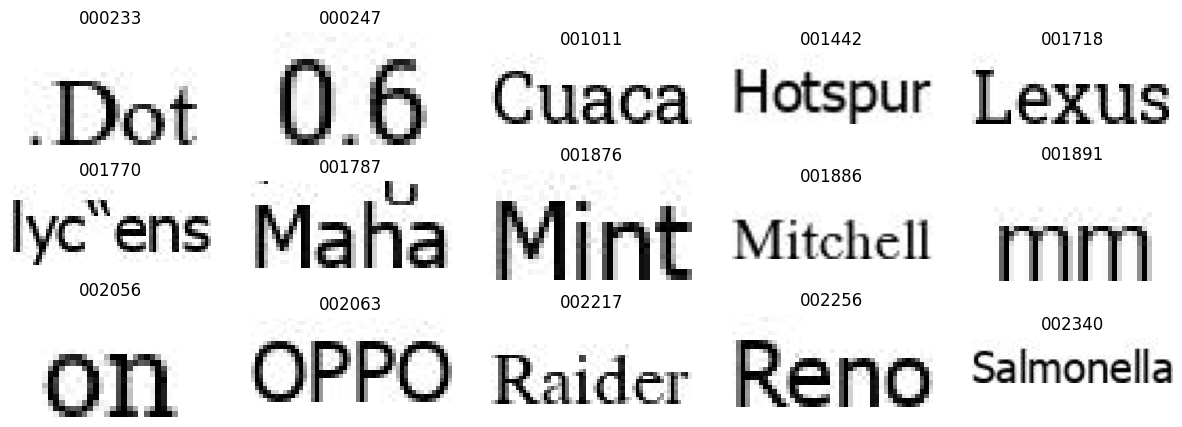

In [6]:
def visualize(dataset_path):
    plt.figure(figsize=(15, 5))
    for i in range(15):
        plt.subplot(3, 5, i+1)
        all_images = os.listdir(f"{dataset_path}/data_train")
        image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
        plt.imshow(image)
        plt.axis('off')
        plt.title(all_images[i].split('.')[0])
    plt.show()

visualize(DatasetConfig.DATA_ROOT)

## Prepare Dataset

In [7]:
train_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None
)
train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)
test_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_test.txt'), header=None
)
test_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

In [ ]:
train_df.head()

In [ ]:
test_df.head()

In [ ]:
!pip install tokenizers


In [49]:
# Function to read vocabulary from a file
def load_vocab(vocab_file):
    with open(vocab_file, 'r', encoding='utf-8') as f:
        vocab = f.read().splitlines()
    return vocab

# Path to your vocabulary file
vocab_file = 'dataset/unique_words.txt'
khmer_vocab = load_vocab(vocab_file)


In [30]:
# tokenizer = AutoTokenizer.from_pretrained("path_to_your_khmer_tokenizer_model")
# processor = TrOCRProcessor.from_pretrained("microsoft/trocr-small-printed", tokenizer=tokenizer)


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [51]:
# Add Khmer vocabulary to the tokenizer
tokenizer.add_tokens(khmer_vocab)


0

In [31]:
# Save the updated tokenizer
tokenizer.save_pretrained("khmer_trocr_tokenizer")


('khmer_trocr_tokenizer/tokenizer_config.json',
 'khmer_trocr_tokenizer/special_tokens_map.json',
 'khmer_trocr_tokenizer/sentencepiece.bpe.model',
 'khmer_trocr_tokenizer/added_tokens.json')

In [8]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, AutoTokenizer
from PIL import Image
# from khmer_tokenizer import KhmerTokenizer  # Example: Custom Khmer tokenizer
tokenizer = AutoTokenizer.from_pretrained('khmer_trocr_tokenizer')

# Initialize TrOCR processor and model
processor = TrOCRProcessor.from_pretrained('microsoft/trocr-small-printed', tokenizer=tokenizer)
# model = VisionEncoderDecoderModel.from_pretrained('microsoft/trocr-small-printed')




Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [27]:
tokenizer = AutoTokenizer.from_pretrained("khmer_trocr_tokenizer")  # Example BERT tokenizer

processor = TrOCRProcessor.from_pretrained("microsoft/trocr-small-printed", tokenizer=tokenizer)


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [11]:
print(model.config)

NameError: name 'model' is not defined

In [12]:
class CustomOCRDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # The image file name.
        file_name = self.df['file_name'][idx]
        # The text (label).
        text = self.df['text'][idx]
        # Read the image, apply augmentations, and get the transformed pixels.
        image = Image.open(self.root_dir + file_name).convert('RGB')
        # image = train_transforms(image)
        pixel_values = self.processor(image, return_tensors='pt').pixel_values
        # Pass the text through the tokenizer and get the labels,
        # i.e. tokenized labels.
        labels =  self.processor.tokenizer(
            text,
            padding='max_length',
            max_length=self.max_target_length 
        ).input_ids
        # We are using -100 as the padding token.
        labels = [label if label !=  self.processor.tokenizer.pad_token_id else -100 for label in labels]
        
       
        # Check if text is empty after tokenization
        if len(labels) == 0 or all(label == -100 for label in labels):
            # Replace with a placeholder or handle as needed
            labels = [ self.processor.tokenizer.pad_token_id]

        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding
        

In [13]:

from transformers import AutoTokenizer, TrOCRProcessor, VisionEncoderDecoderModel, ViTConfig, BertConfig


In [44]:
# Initialize VisionEncoderDecoderModel
config_encoder = ViTConfig.from_pretrained("google/vit-base-patch16-384")  # Example ViT encoder config
config_decoder = BertConfig.from_pretrained("bert-base-multilingual-cased")  # Example BERT decoder config
config = VisionEncoderDecoderConfig.from_encoder_decoder_configs(config_encoder, config_decoder)

model = VisionEncoderDecoderModel(config=config)


/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

In [ ]:
print(model.config)

In [46]:
# Resize token embeddings if necessary
model.decoder.resize_token_embeddings(len(tokenizer))

Embedding(76176, 768)

In [ ]:
# Function to process an image and text
def process_example(image_path, text):
    image = Image.open(image_path).convert('RGB')
    pixel_values = processor(image, return_tensors='pt').pixel_values

    labels = tokenizer(
        text,
        padding='max_length',
        max_length=128,  # Adjust as needed
        truncation=True,
        return_tensors="pt"
    ).input_ids

    labels[labels == tokenizer.pad_token_id] = -100  # Adjust padding token handling

    return {"pixel_values": pixel_values, "labels": labels}

In [ ]:

# # Function to process an image and text
# def process_example(image_path, text):
#     image = Image.open(image_path).convert('RGB')
#     pixel_values = processor(image, return_tensors='pt').pixel_values

#     labels = tokenizer(
#         text,
#         padding='max_length',
#         max_length=64,  # Adjust as needed
#         truncation=True,
#         return_tensors="pt"
#     ).input_ids

#     labels[labels == tokenizer.pad_token_id] = -100  # Adjust padding token handling

#     return {"pixel_values": pixel_values, "labels": labels}

# # Example usage
# image_path = "dataset/data_train/000000.jpg"
# khmer_text = "!(ម៉ានីល"

# example = process_example(image_path, khmer_text)
# print("Processed Example:", example)

# # Ensure the model is moved to the correct device
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model.to(device)

# # Print shapes for debugging
# print(f"Pixel values shape: {example['pixel_values'].shape}")
# print(f"Labels shape: {example['labels'].shape}")

# # Dummy forward pass to check for CUDA issues
# try:
#     inputs = example["pixel_values"].unsqueeze(0).to(device)  # Add batch dimension
#     labels = example["labels"].unsqueeze(0).to(device)  # Add batch dimension

#     outputs = model(pixel_values=inputs, labels=labels)
    
#     # Unpack the outputs correctly
#     loss = outputs.loss
#     logits = outputs.logits

#     print("Loss:", loss)
#     print("Logits:", logits)
# except Exception as e:
#     print(f"An error occurred: {e}")

In [1]:
# Example usage assuming `df` is your DataFrame and `processor` is your processor object
# Initialize dataset
dataset = CustomOCRDataset(root_dir='dataset/data_train/', df=train_df, processor=processor, max_target_length=32)

# Example: Print label IDs for the first example in the dataset
print(dataset[1])


NameError: name 'CustomOCRDataset' is not defined

In [70]:
from transformers import NllbTokenizer

# Example token IDs (replace with actual token IDs from your dataset)
token_ids = [  0, 64009,     2,  -100,  -100,  -100]

# Load the tokenizer used in your CustomOCRDataset
# tokenizer = AutoTokenizer.from_pretrained("khmer_tokenizer")
# tokenizer = AutoTokenizer.from_pretrained("GKLMIP/bert-khmer-small-uncased-tokenized")

# Ensure all token IDs are valid
valid_token_ids = [tid for tid in token_ids if tid != -100]

# Decode token IDs to text
decoded_text = processor.batch_decode(valid_token_ids, skip_special_tokens=True)

print("Decoded Text:", decoded_text)


Decoded Text: ['', '$369', '']


In [ ]:
# # Load the custom BERT tokenizer for Khmer text
# tokenizer = BertTokenizer(vocab_file=ModelConfig.VOCAB_FILE)
# processor =TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME ,tokenizer=tokenizer)

In [47]:


train_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_train/'),
    df=train_df,
    # tokenizer = tokenizer,
    processor=processor
)
valid_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_test/'),
    df=test_df,
    # tokenizer = tokenizer,
    processor=processor
)

In [48]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(valid_dataset))

Number of training examples: 22567
Number of validation examples: 5640


In [49]:
encoding = train_dataset[0]
for k,v in encoding.items():
    print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


(-0.5, 50.5, 24.5, -0.5)

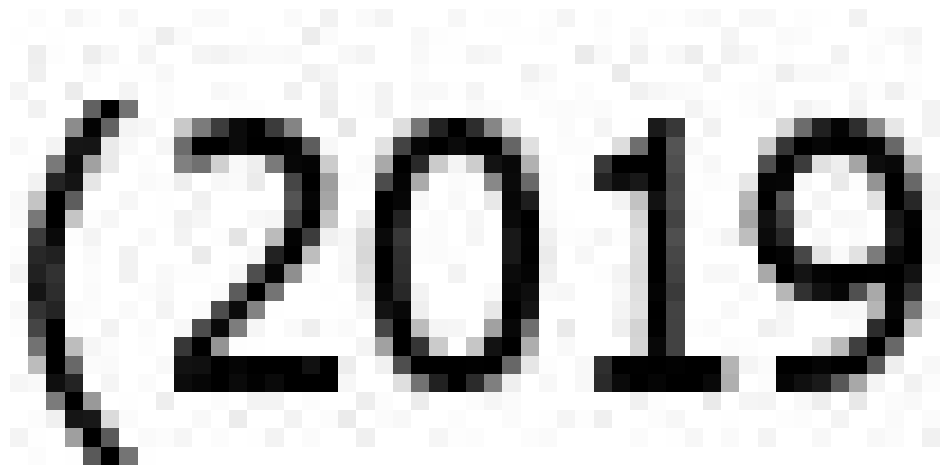

In [31]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][12]).convert("RGB")
# image = train_transforms(image)
plt.imshow(image)
plt.axis('off')

In [ ]:
# labels = encoding['labels']
# labels[labels == -100] = processor.tokenizer.pad_token_id
# label_str = processor.decode(labels, skip_special_tokens=True)
# print(label_str)

In [50]:
# Test data loading and processing
encoding = train_dataset[0]
print("Pixel Values Shape:", encoding['pixel_values'].shape)

labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.tokenizer.decode(labels, skip_special_tokens=True)
print("Decoded Labels:", label_str)

Pixel Values Shape: torch.Size([3, 384, 384])
Decoded Labels: !(ម៉ានីល


In [51]:
id = processor.tokenizer.encode('ទាំង')
print(id)

[0, 69100, 2]


In [52]:
decode = processor.tokenizer.decode(id)
print(decode)

<s>ទាំង</s>


In [35]:
# Print the vocabulary size
print(f"Vocabulary size: {len(processor.tokenizer)}")


Vocabulary size: 76176


## Initialize the Model

In [53]:
# model = VisionEncoderDecoderModel.from_pretrained(ModelConfig.MODEL_NAME)
model.to(device)
print(model)
# Total parameters and trainable parameters.
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_featur

## Model Configurations

In [ ]:
# # Set special tokens used for creating the decoder_input_ids from the labels.
# model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
# model.config.pad_token_id = processor.tokenizer.pad_token_id
# # Set Correct vocab size.
# # model.config.vocab_size = model.config.decoder.vocab_size
# # model.config.eos_token_id = processor.tokenizer.sep_token_id
# # Set Correct vocab size.
# model.config.vocab_size = processor.tokenizer.vocab_size  # Assuming this is correct for your tokenizer

# model.config.eos_token_id = processor.tokenizer.sep_token_id

# model.config.max_length = 64
# model.config.early_stopping = True
# model.config.no_repeat_ngram_size = 3
# model.config.length_penalty = 2.0
# model.config.num_beams = 4

In [54]:
# Configure model settings
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.vocab_size = processor.tokenizer.vocab_size
model.config.eos_token_id = processor.tokenizer.sep_token_id
model.config.max_length = 64
model.config.early_stopping = True
model.config.no_repeat_ngram_size = 3
model.config.length_penalty = 2.0
model.config.num_beams = 4

We use the AdamW optimizer here with a weight decay of 0.0005.

In [55]:
optimizer = optim.AdamW(
    model.parameters(), lr=TrainingConfig.LEARNING_RATE, weight_decay=0.0005
)

## Evaluation Metric

In [56]:
cer_metric = evaluate.load('cer')

In [ ]:
# from datasets import load_metric

# cer_metric = load_metric("cer")

In [57]:
def compute_cer(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    cer = cer_metric.compute(predictions=pred_str, references=label_str)

    return {"cer": cer}

In [73]:
def compute_cer(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    # Filter out empty strings
    filtered_pred_str = []
    filtered_label_str = []
    for p, l in zip(pred_str, label_str):
        if p.strip() != "" and l.strip() != "":
            filtered_pred_str.append(p)
            filtered_label_str.append(l)

    cer = cer_metric.compute(predictions=filtered_pred_str, references=filtered_label_str)

    return {"cer": cer}


## Training and Validation Loops

In [71]:
training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    eval_strategy='epoch',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=True,
    output_dir='ocrmodel/',
    logging_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=5,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS
)

In [ ]:
# training_args = Seq2SeqTrainingArguments(
#     predict_with_generate=True,
#     eval_strategy='epoch',  # Evaluate at end of each epoch
#     per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
#     per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
#     fp16=True,  # Use mixed precision training if possible
#     output_dir='seq2seq_model_printed/',  # Directory to save models and results
#     logging_strategy='epoch',  # Log metrics at end of each epoch
#     save_strategy='epoch',  # Save model at end of each epoch
#     save_total_limit=5,  # Limit total number of saved checkpoints
#     report_to='tensorboard',  # Report metrics to TensorBoard
#     num_train_epochs=TrainingConfig.EPOCHS,  # Number of training epochs
#     # Add more arguments as needed for early stopping, gradient accumulation, etc.
# )


In [74]:
# Initialize trainer.
from transformers import default_data_collator

trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.tokenizer,
    args=training_args,
    compute_metrics=compute_cer,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=default_data_collator
)



In [ ]:
# Check batch data shapes
for batch in train_dataset:
    for k, v in batch.items():
        print(f"{k}: {v.shape}")
    break  # Print the shapes for the first batch only

In [ ]:
import gc
torch.cuda.empty_cache()
gc.collect()

In [ ]:
import torch
print(torch.cuda.is_available())


In [ ]:
def training_step(model, inputs):
    # Check input shapes
    for name, input_tensor in inputs.items():
        print(f"{name} shape: {input_tensor.shape}")
    
    # Forward pass
    outputs = model(**inputs)
    
    # Check output shapes
    for name, output_tensor in outputs.items():
        print(f"{name} shape: {output_tensor.shape}")
    
    # Loss computation
    loss = outputs.loss
    return loss

try:
    res = trainer.train()
except RuntimeError as e:
    print(f"RuntimeError: {e}")


## Train

In [75]:
trainer.train()

/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Epoch,Training Loss,Validation Loss,Cer
1,3.235800,5.060669,1.008164
2,3.548200,4.723651,1.001627
3,3.117700,4.791226,1.033921
4,3.008600,4.850622,0.971224
5,2.929300,4.790567,1.032274
6,2.861800,4.928708,0.983099
7,2.805500,4.976037,1.013472
8,2.761200,4.947616,1.008922
9,2.730000,4.849912,0.996274
10,2.700800,4.877790,0.983826


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'max_length': 64, 'early_stopping': True, 'num_beams': 4, 'length_penalty': 2.0, 'no_repeat_ngram_size': 3}
/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in 

TrainOutput(global_step=14110, training_loss=2.969889795856219, metrics={'train_runtime': 12821.9631, 'train_samples_per_second': 17.6, 'train_steps_per_second': 1.1, 'total_flos': 1.2025757641817457e+20, 'train_loss': 2.969889795856219, 'epoch': 10.0})

In [76]:
res

NameError: name 'res' is not defined

## Inference

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [78]:
processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)

# Specify the checkpoint path
checkpoint_path = 'ocrmodel/checkpoint-14110'

# Load the model from the checkpoint
trained_model = VisionEncoderDecoderModel.from_pretrained(checkpoint_path).to(device)

# trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel/checkpoint-'+str(res.global_step)).to(device)

In [79]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    return image

In [80]:
def ocr(image, processor, model):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

In [81]:
def eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=50
):
    image_paths = glob.glob(data_path)
    for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
        if i == num_samples:
            break
        image = read_and_show(image_path)
        text = ocr(image, processor, trained_model)
        plt.figure(figsize=(7, 4))
        plt.imshow(image)
        plt.title(text)
        plt.axis('off')
        plt.show()

In [ ]:
pip install ipywidgets


  0%|          | 0/22567 [00:00<?, ?it/s]

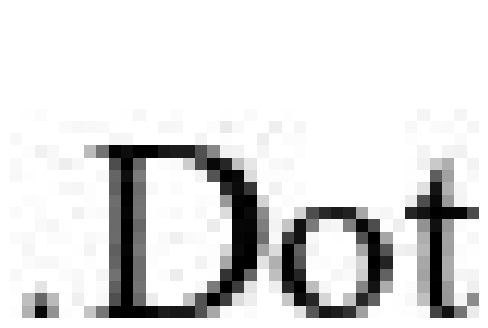

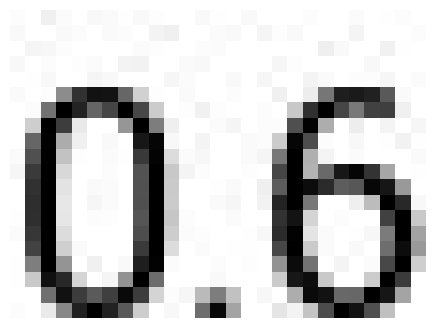

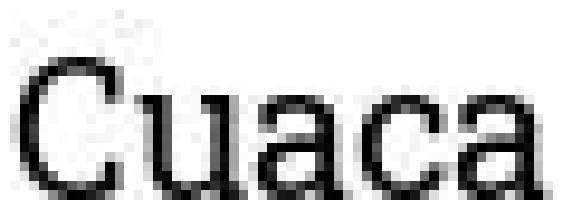

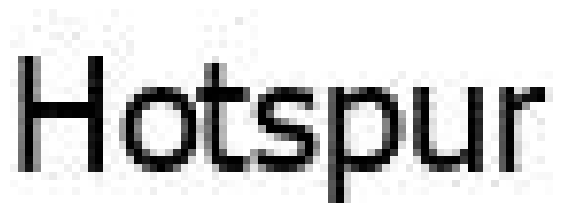

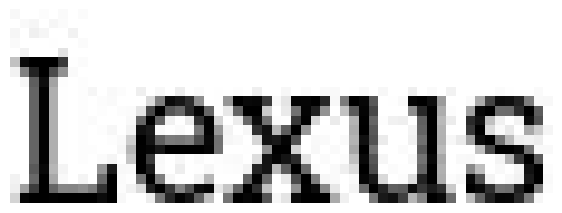

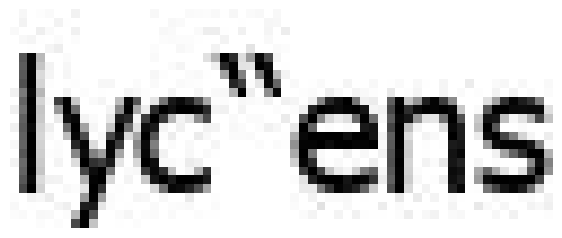

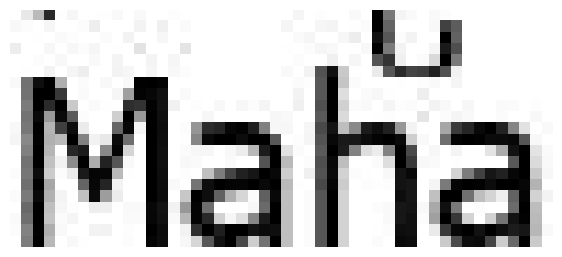

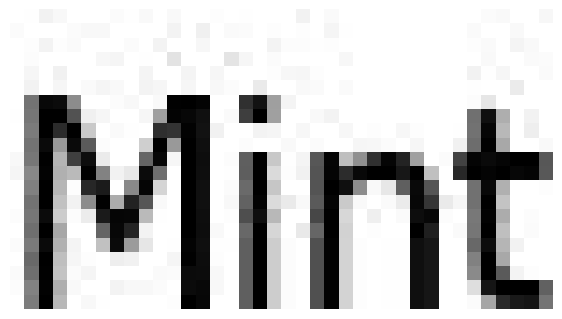

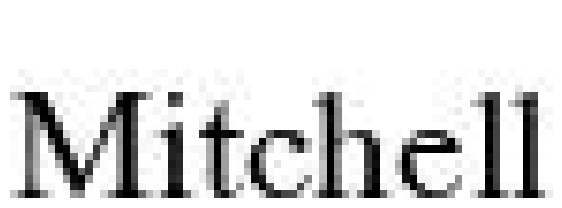

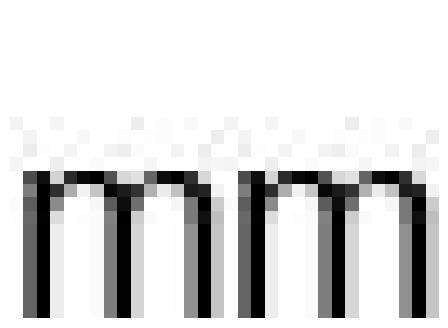

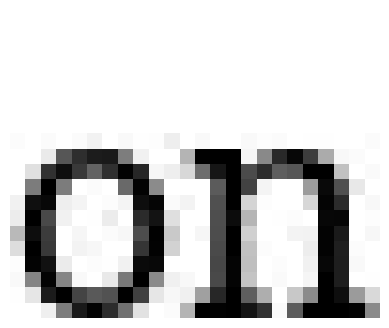

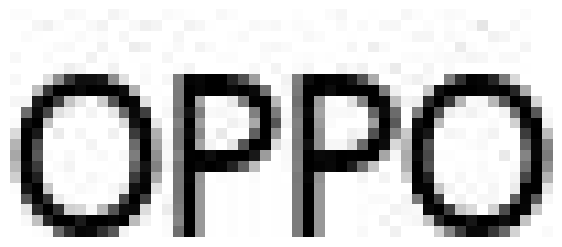

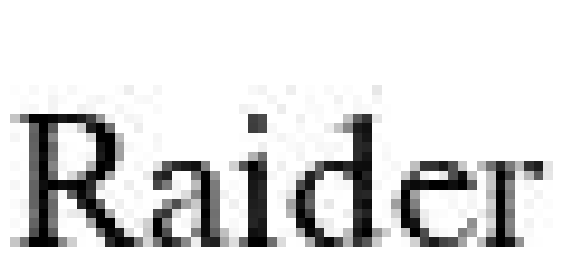

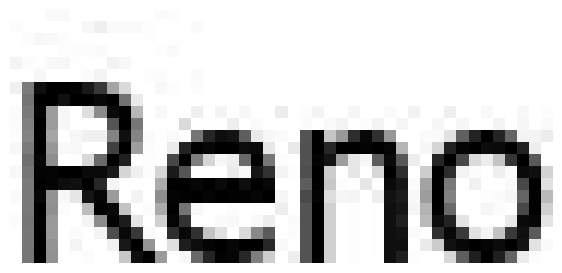

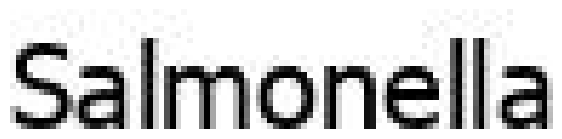

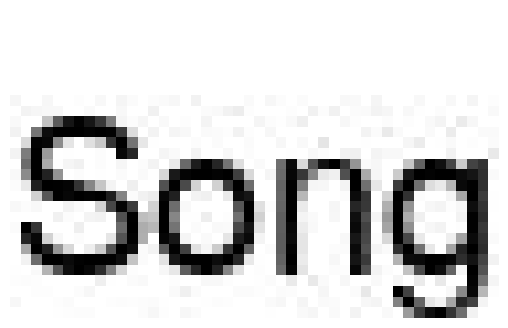

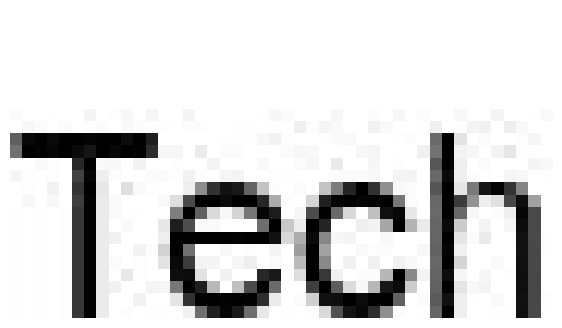

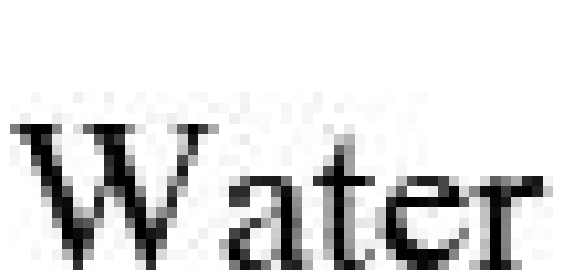

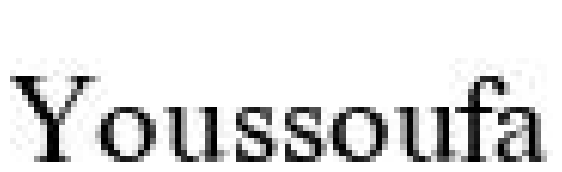

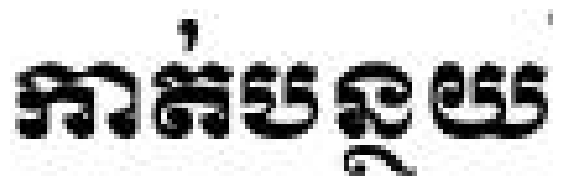

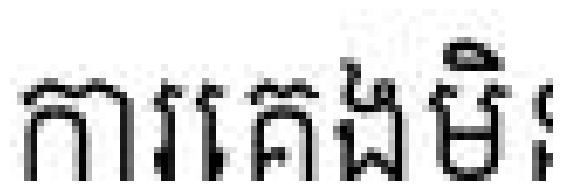

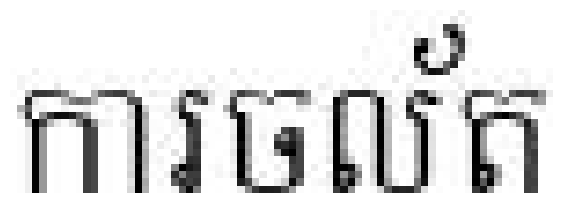

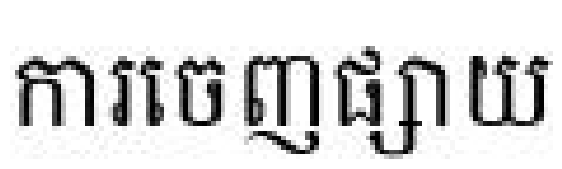

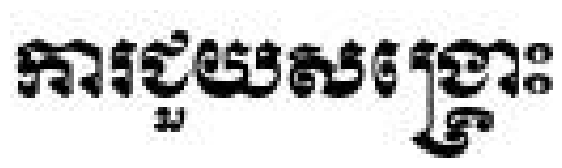

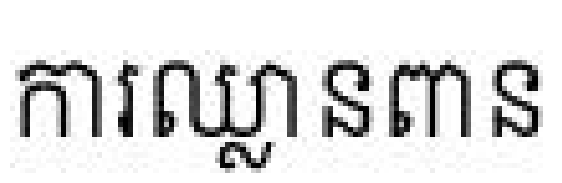

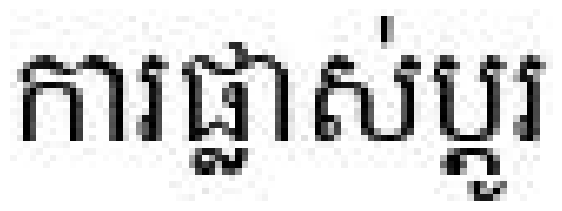

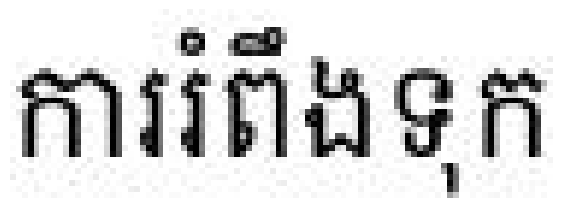

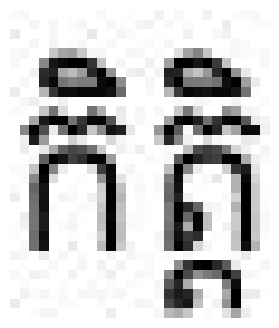

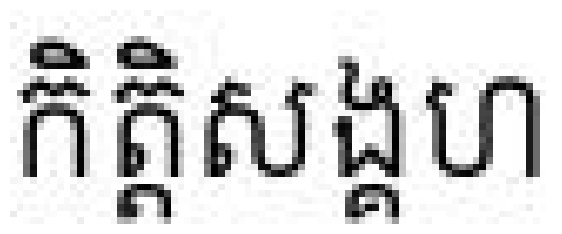

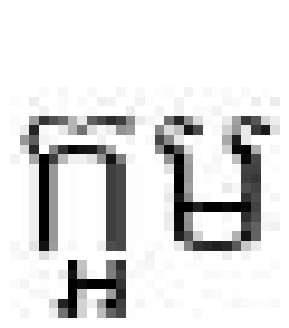

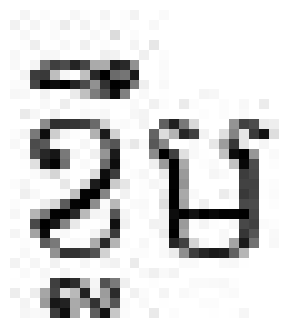

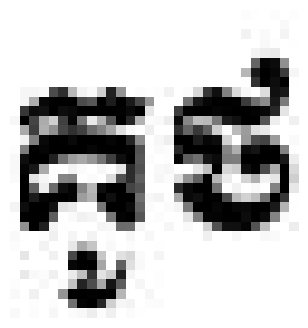

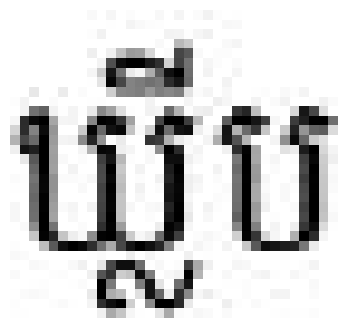

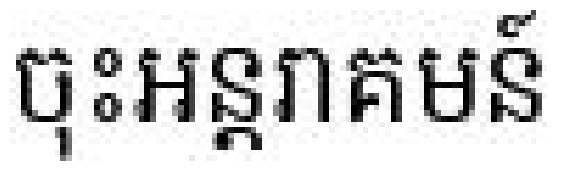

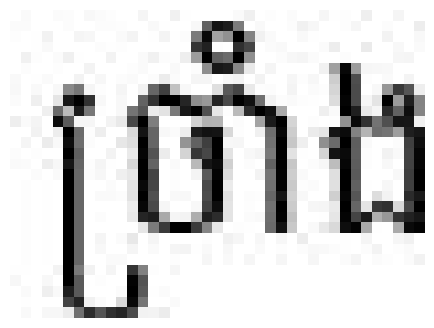

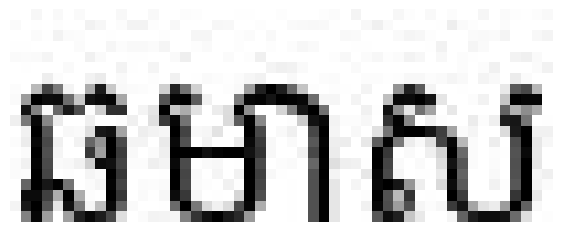

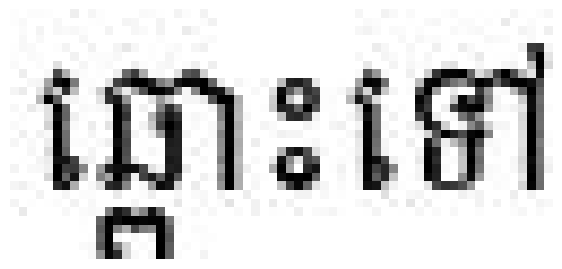

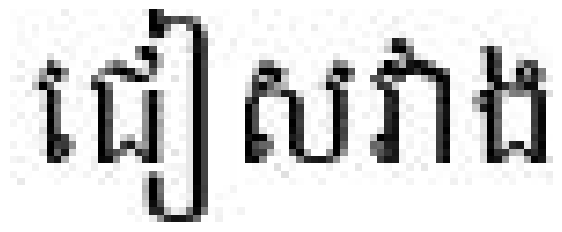

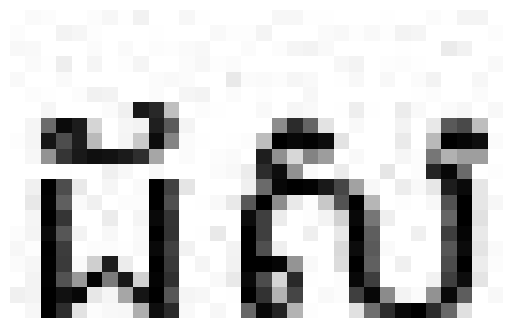

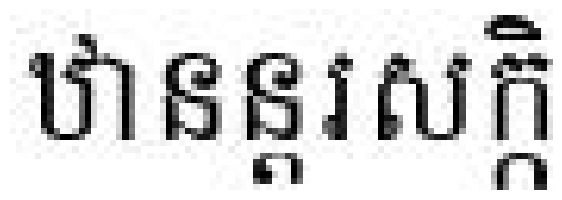

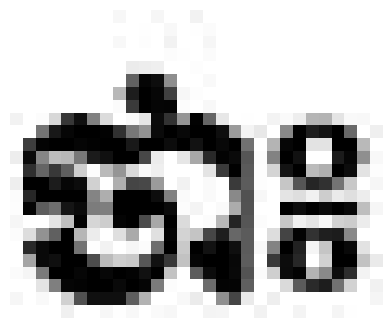

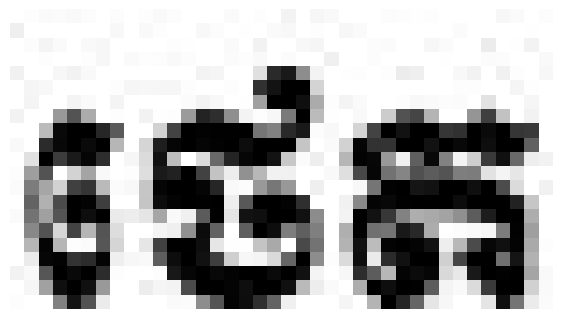

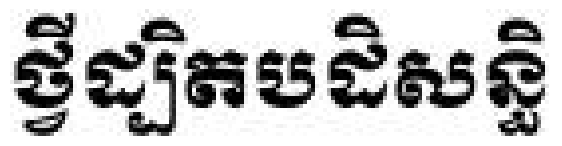

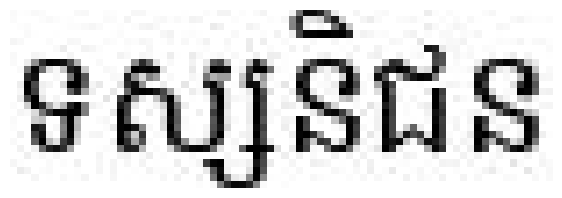

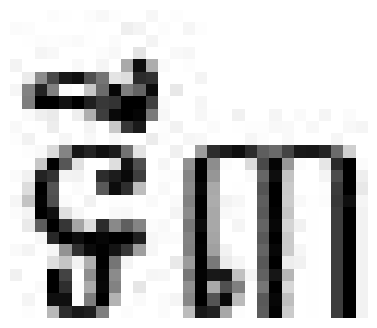

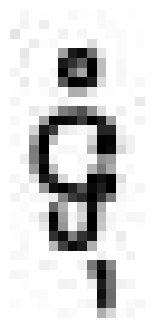

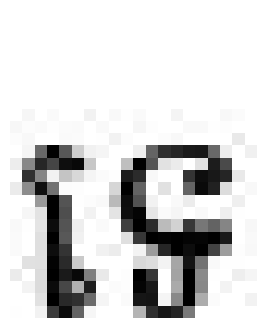

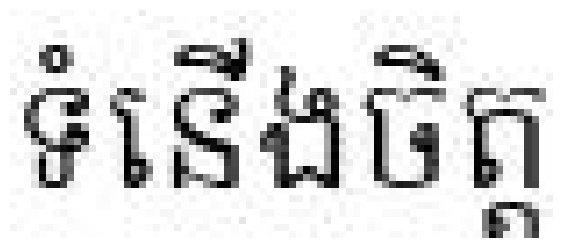

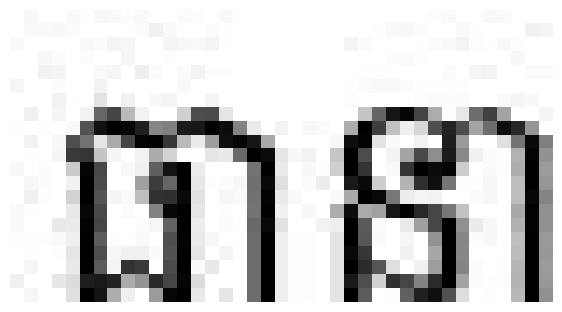

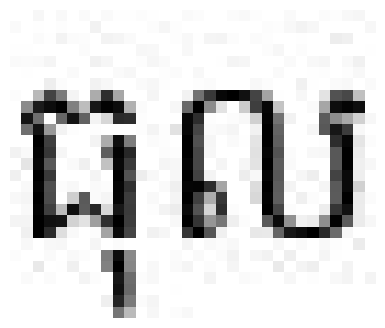

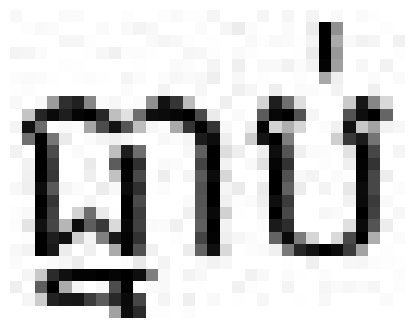

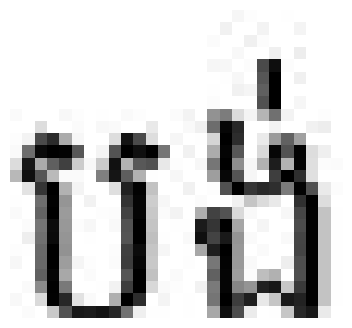

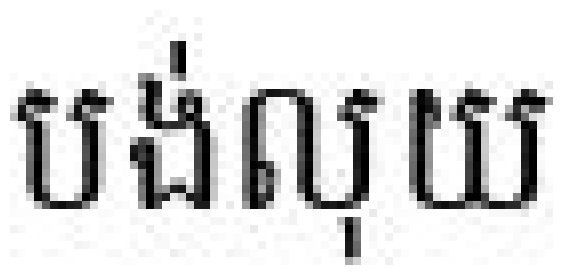

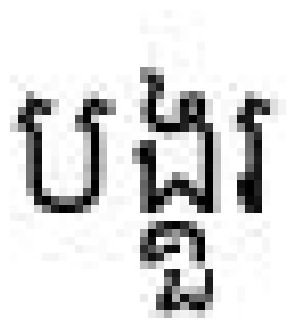

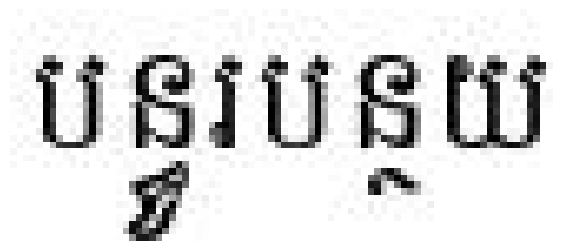

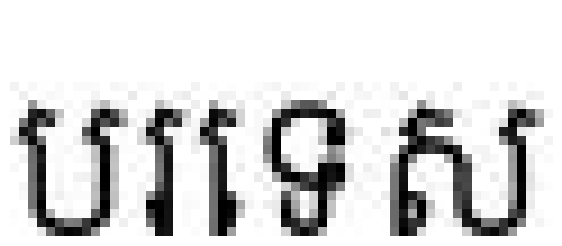

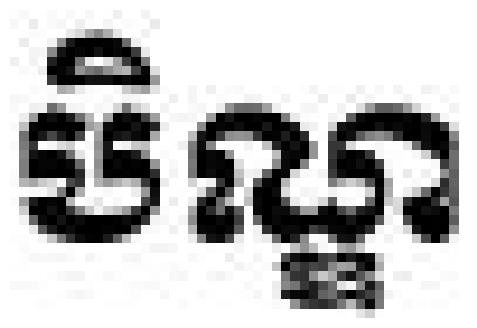

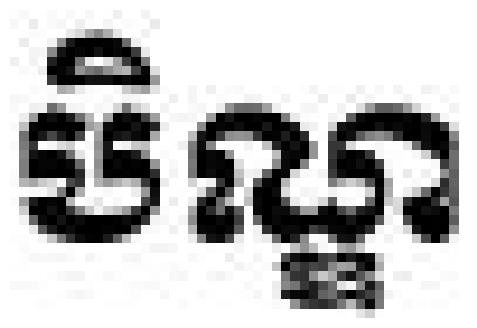

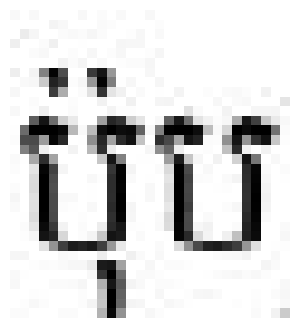

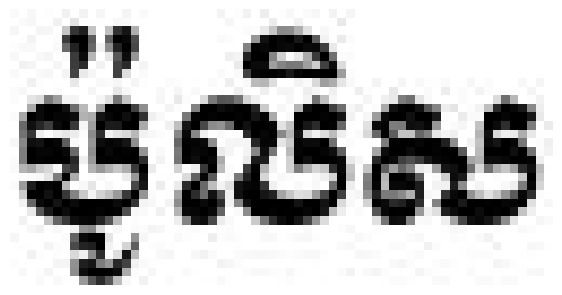

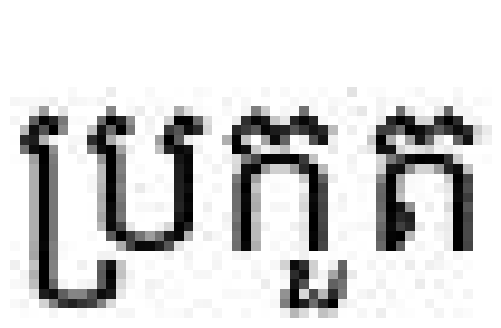

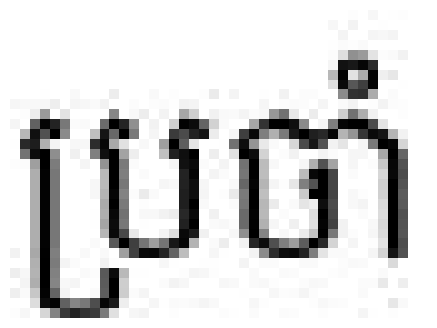

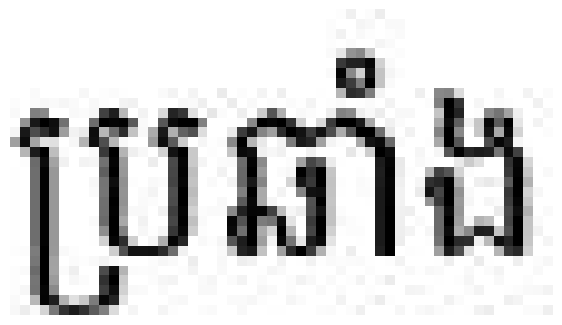

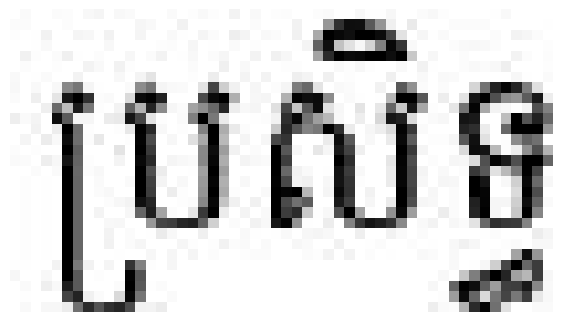

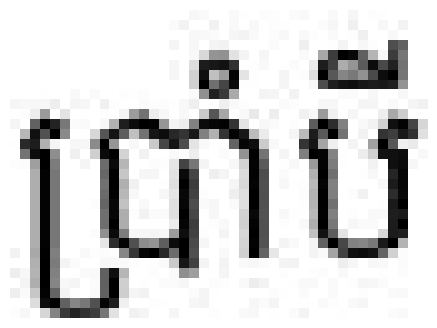

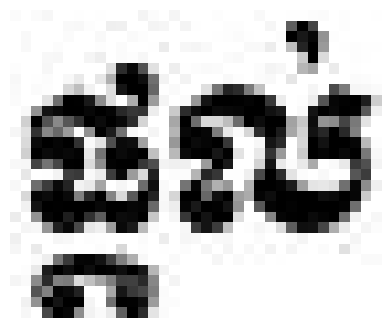

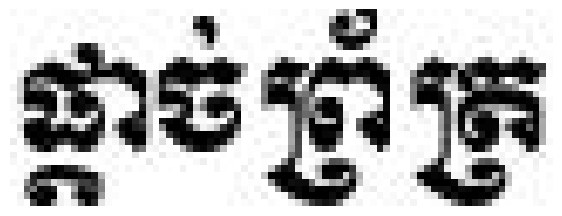

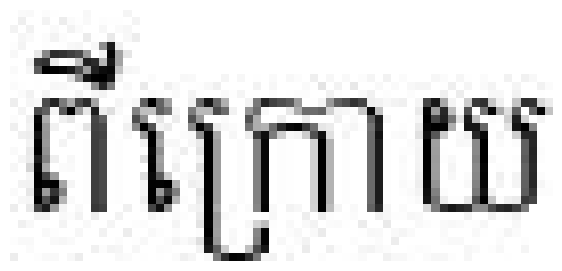

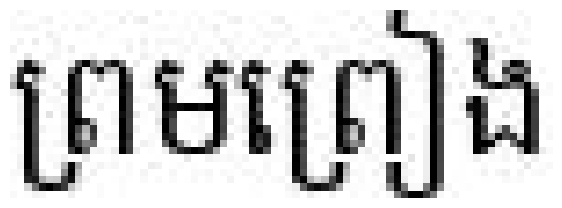

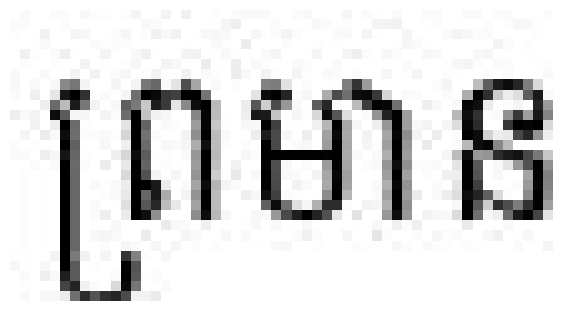

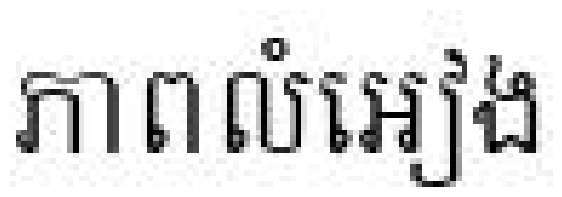

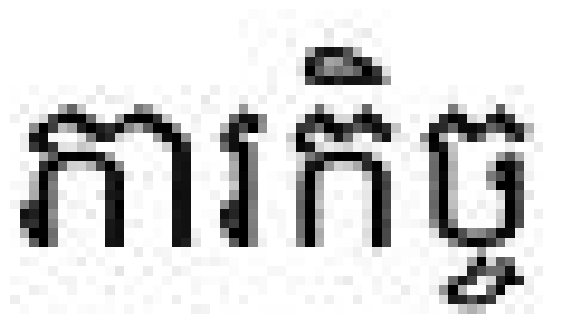

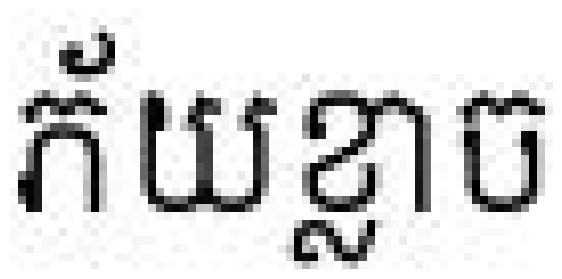

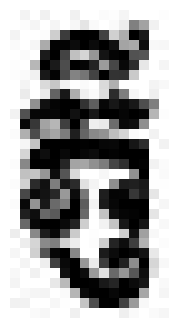

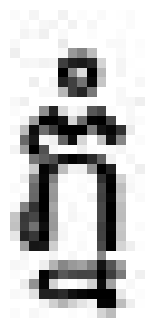

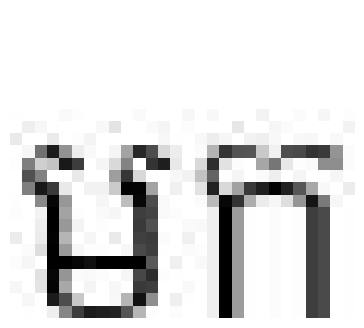

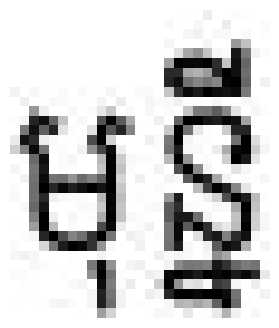

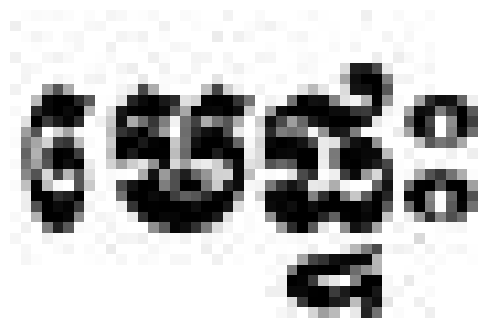

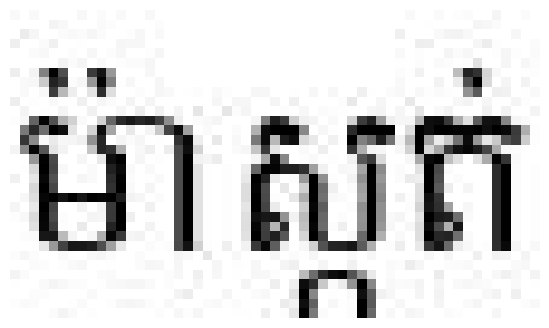

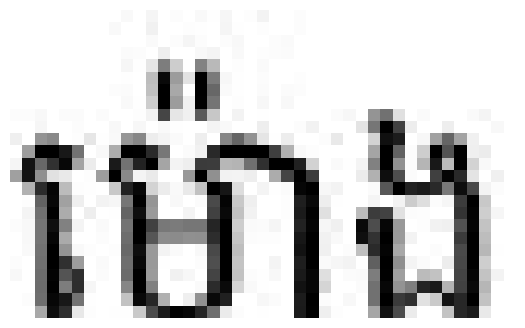

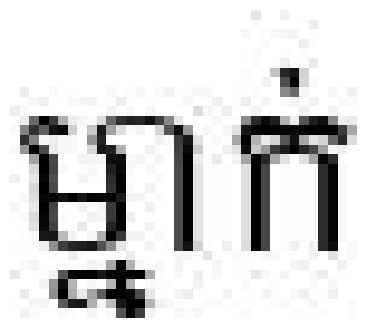

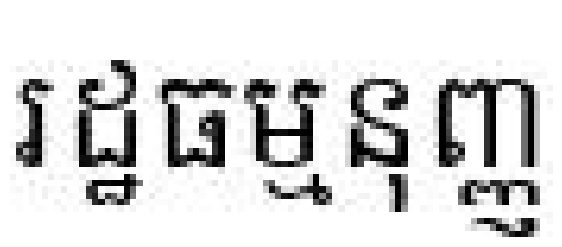

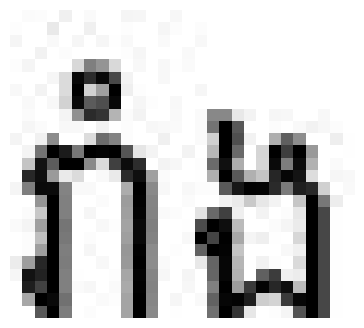

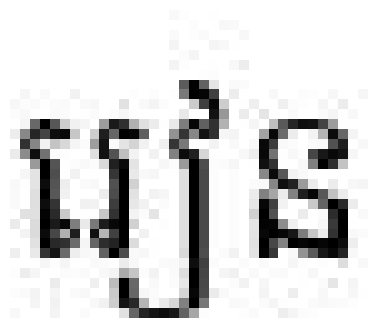

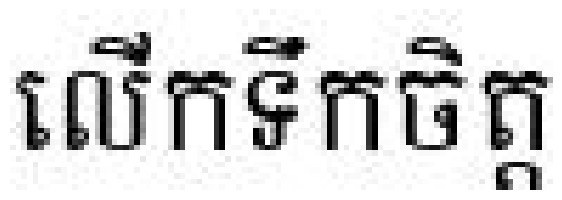

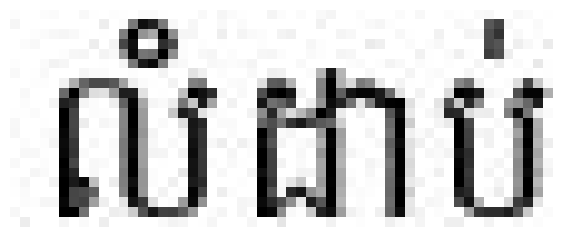

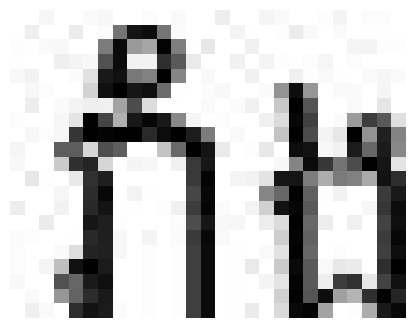

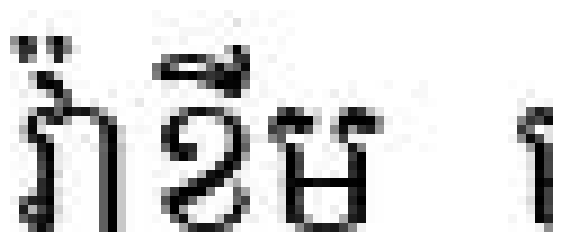

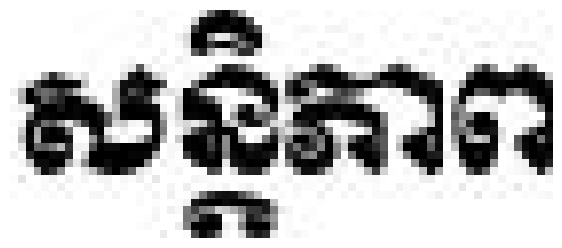

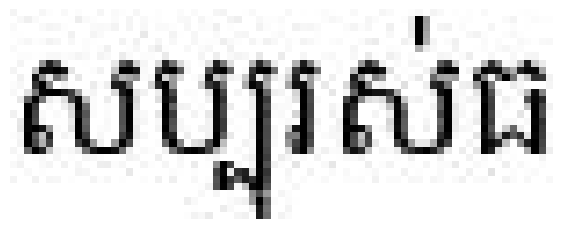

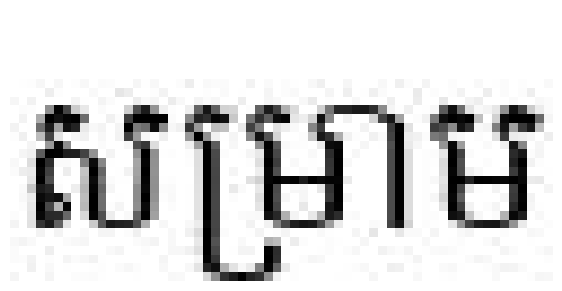

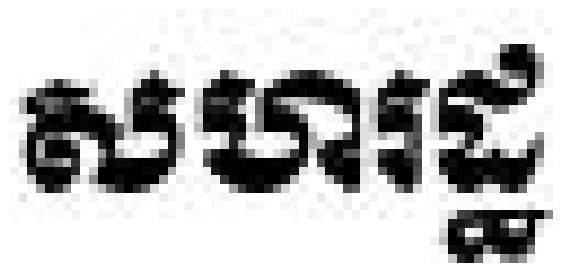

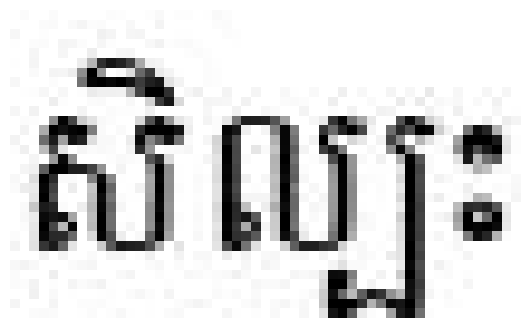

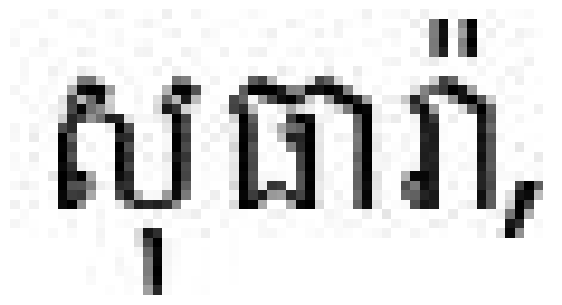

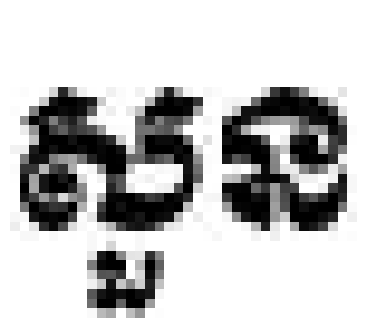

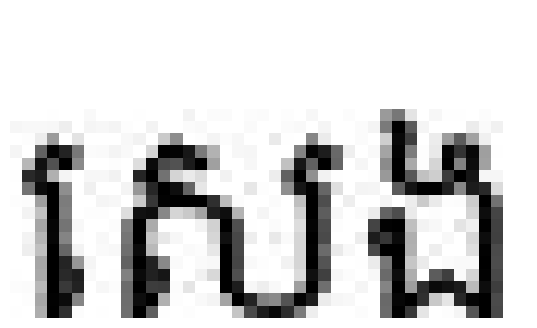

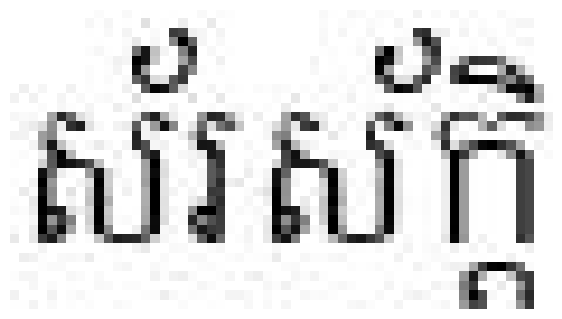

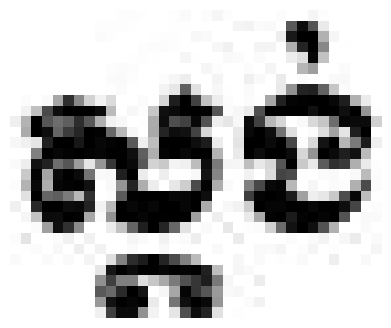

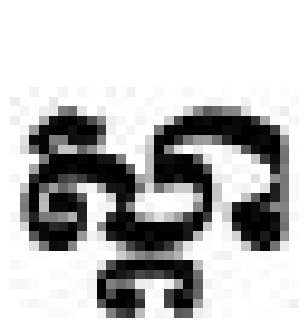

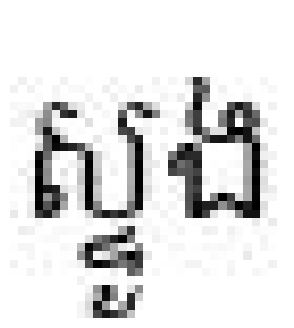

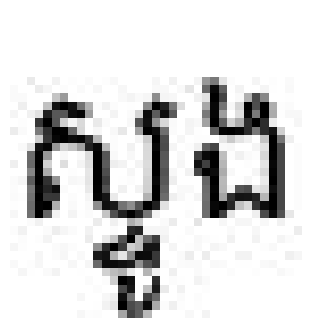

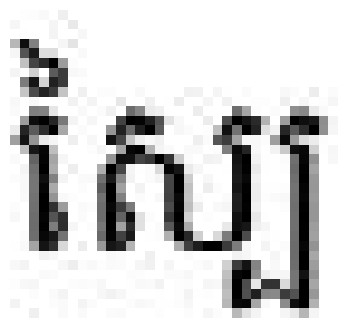

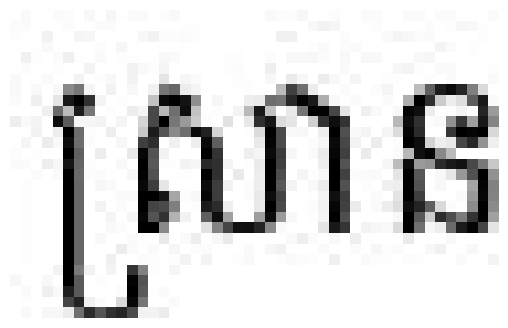

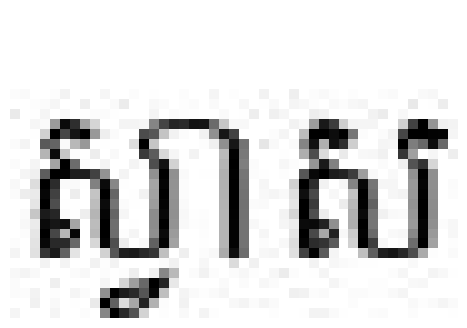

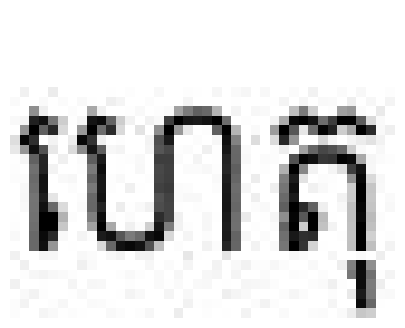

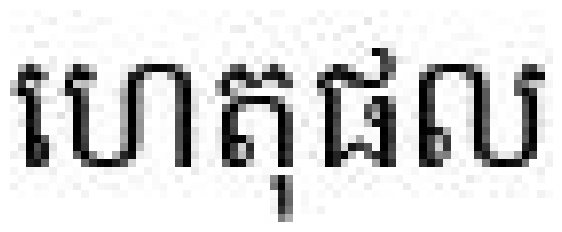

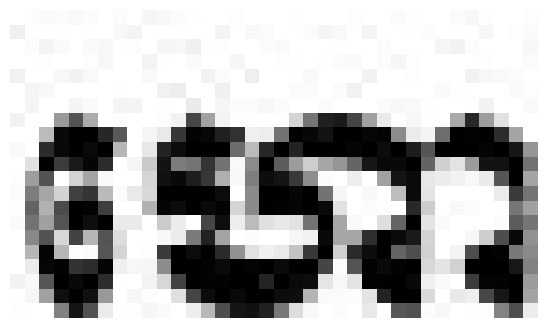

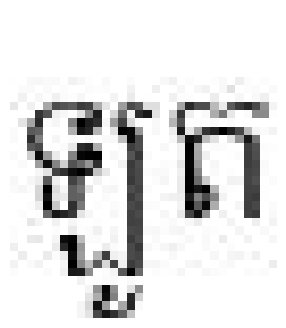

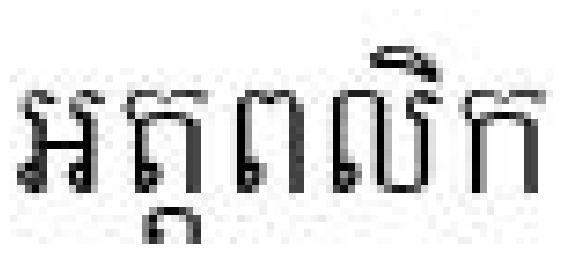

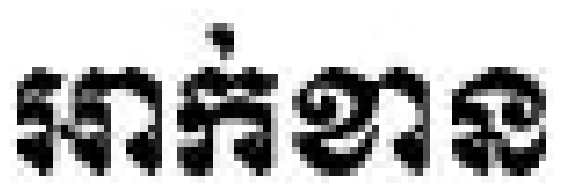

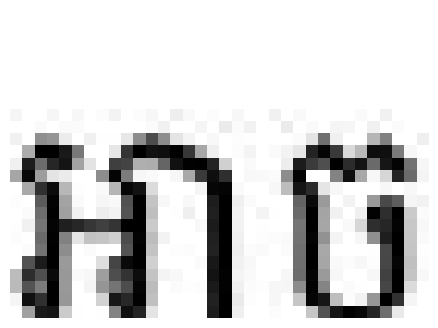

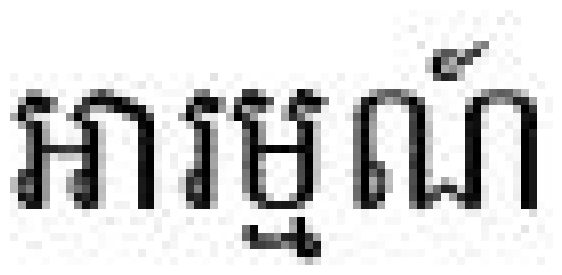

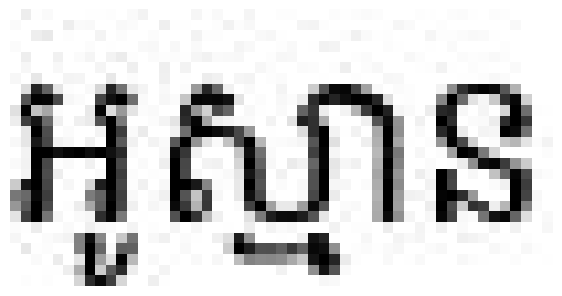

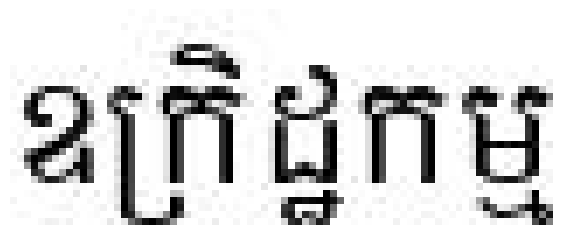

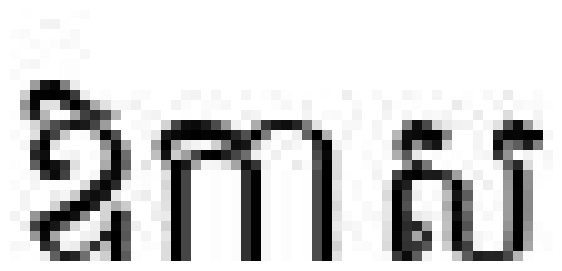

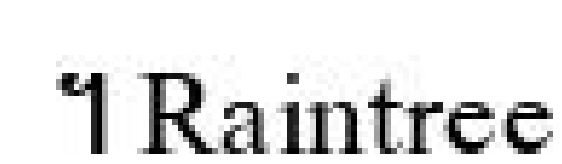

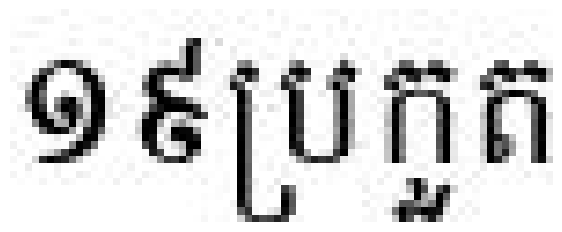

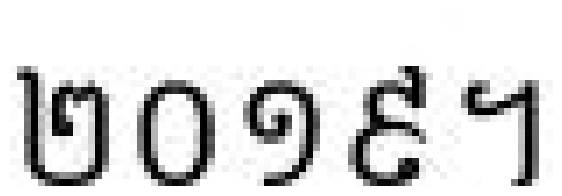

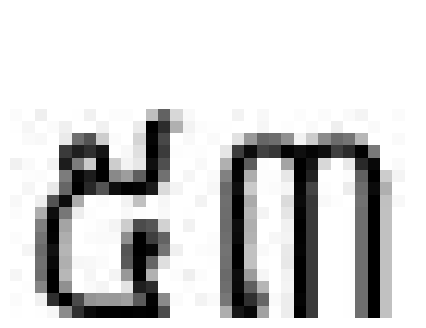

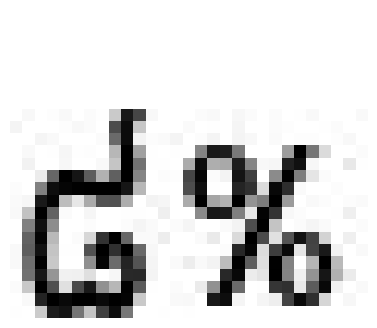

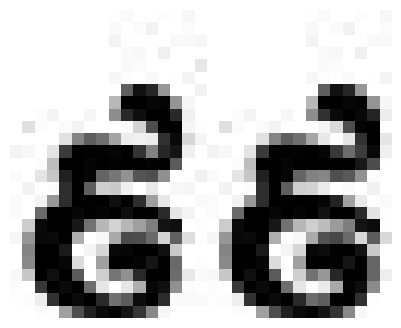

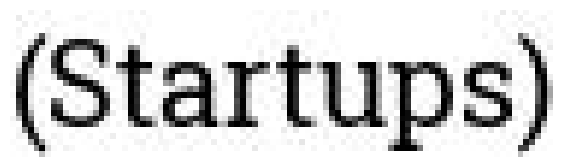

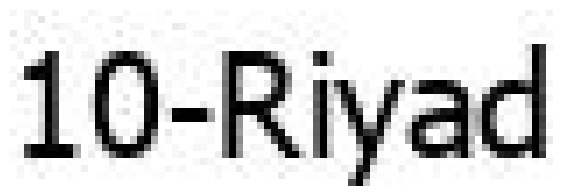

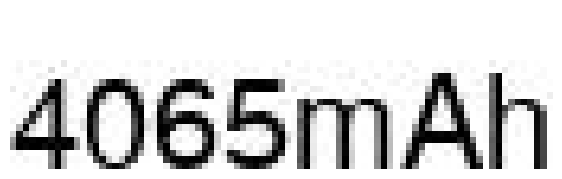

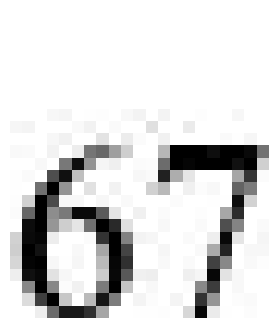

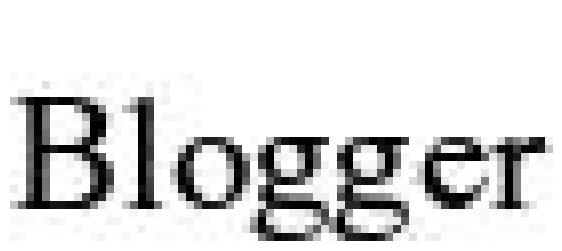

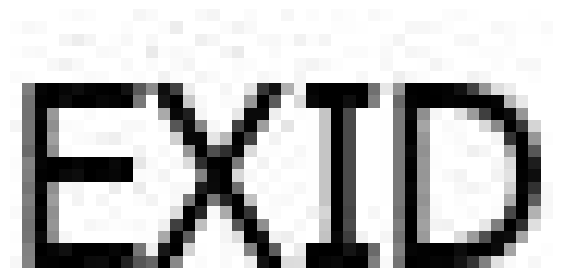

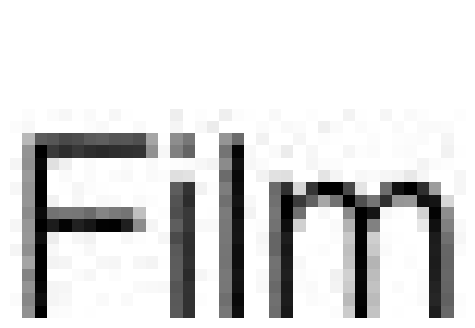

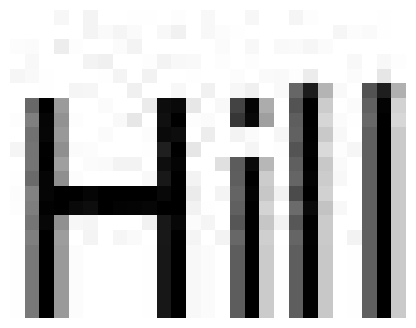

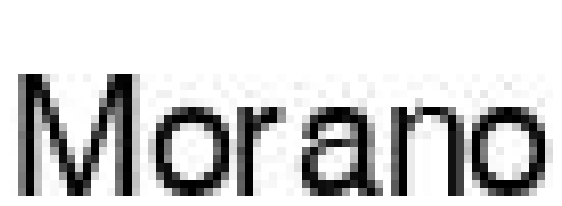

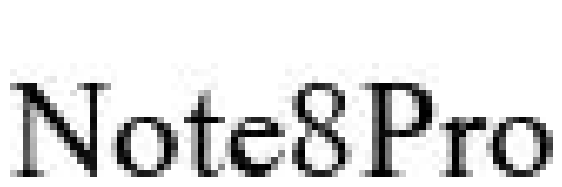

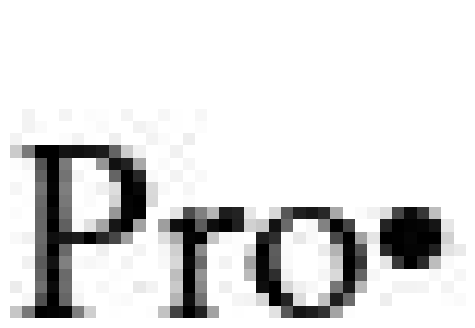

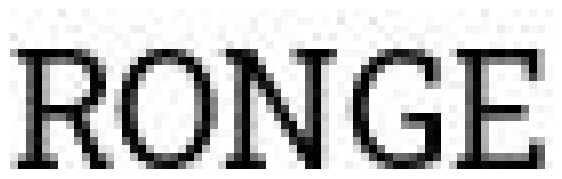

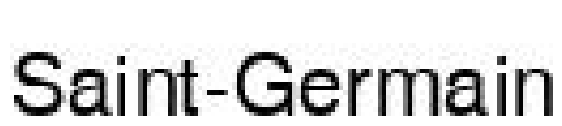

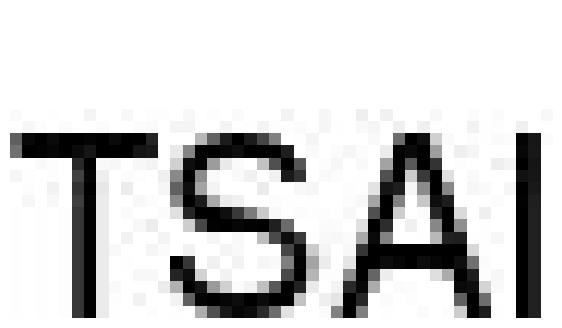

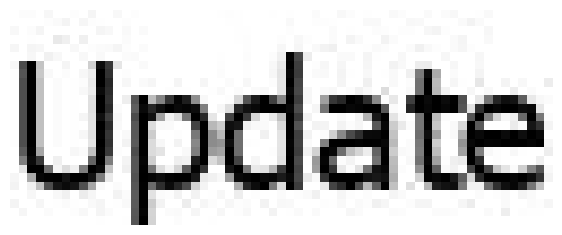

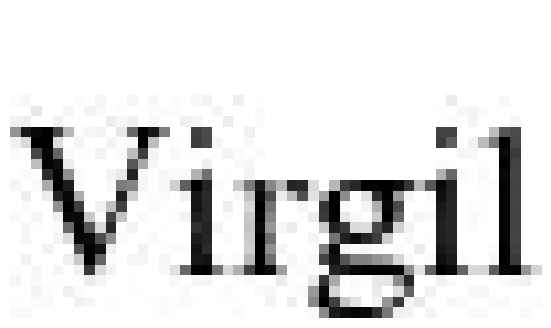

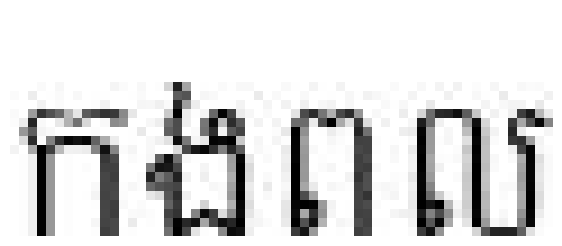

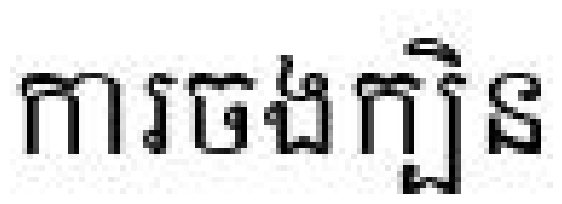

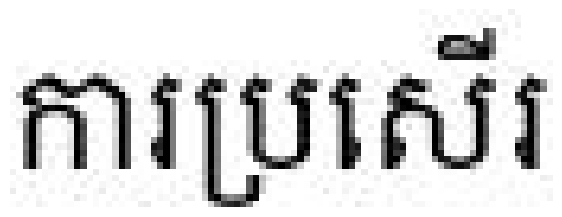

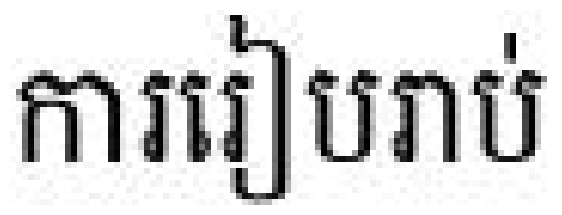

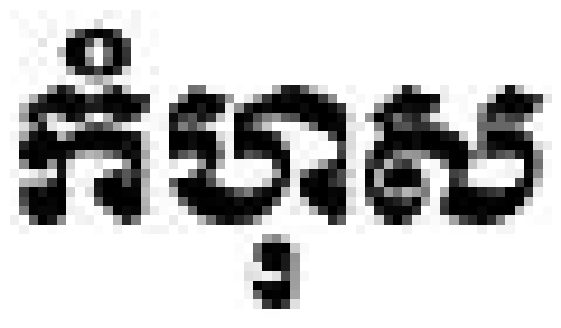

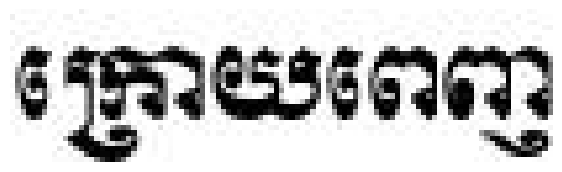

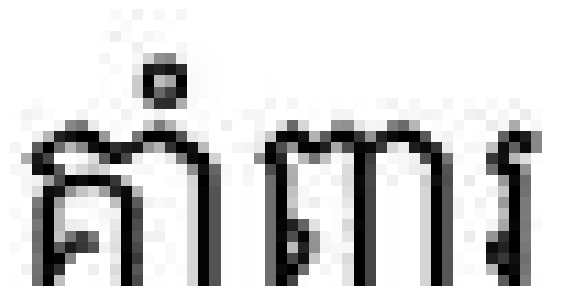

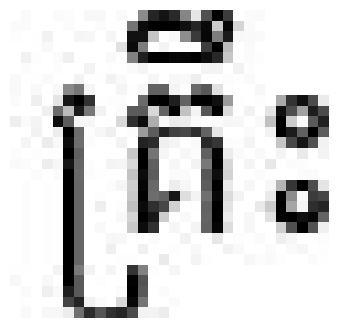

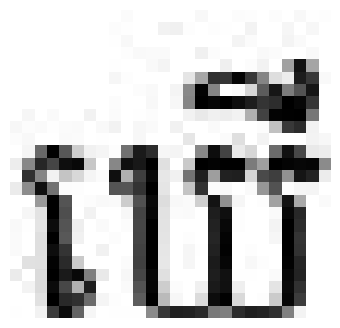

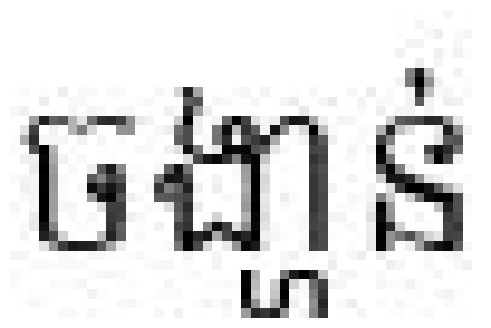

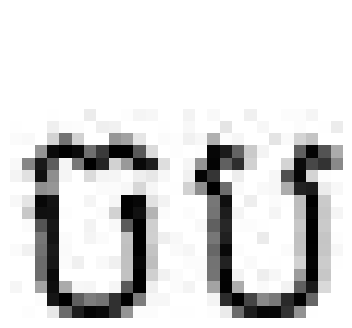

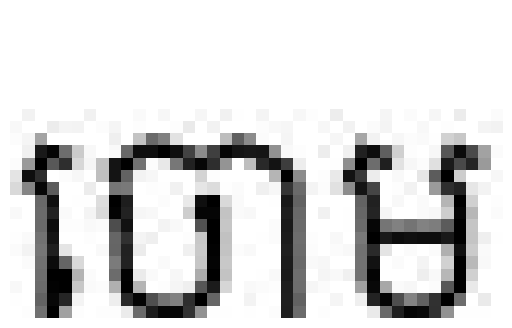

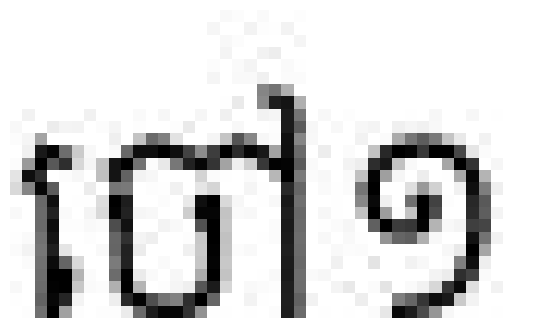

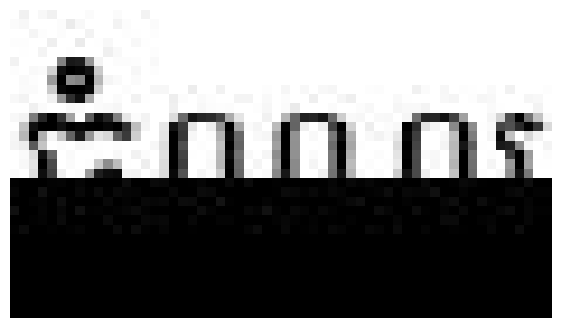

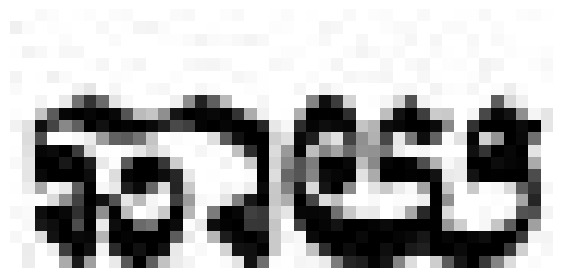

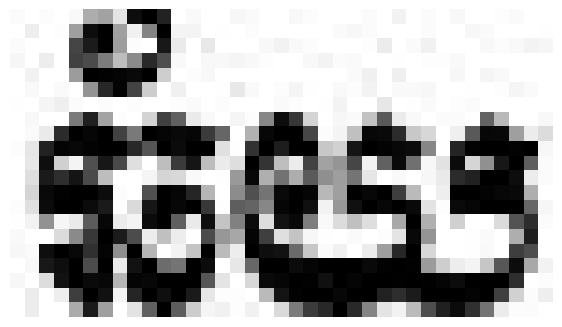

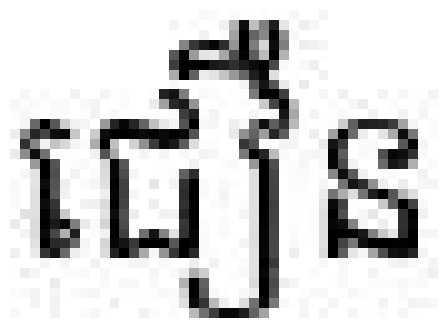

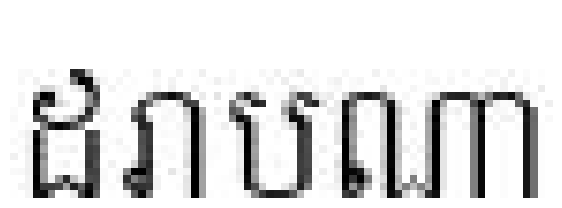

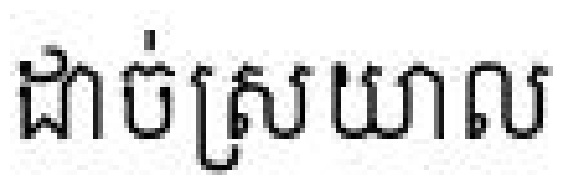

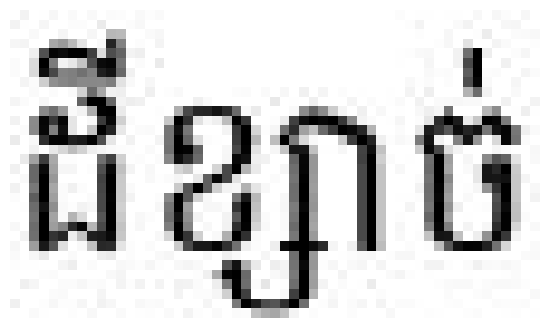

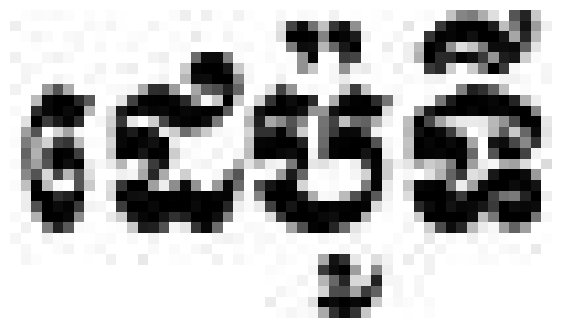

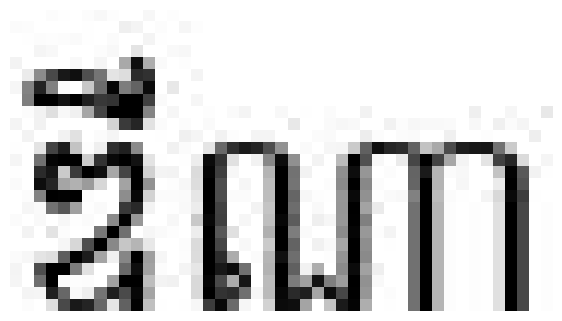

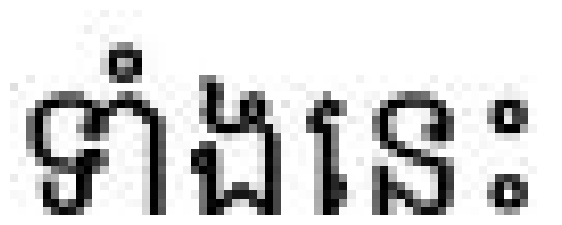

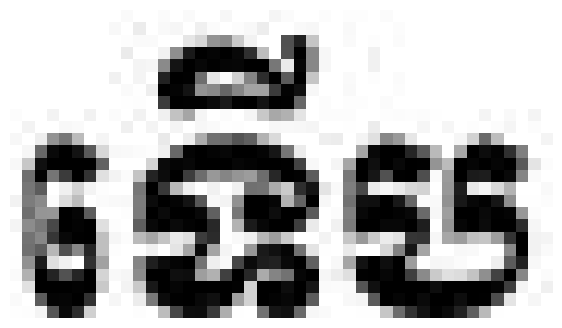

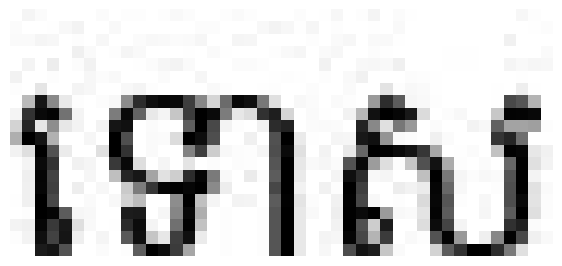

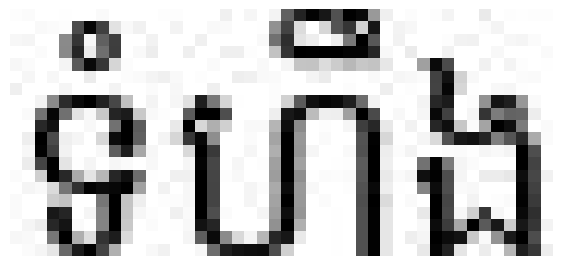

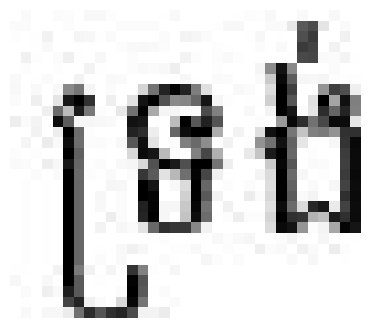

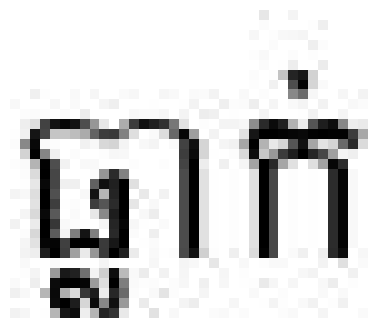

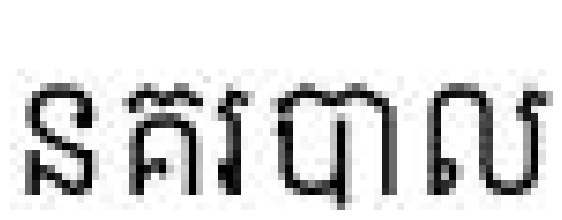

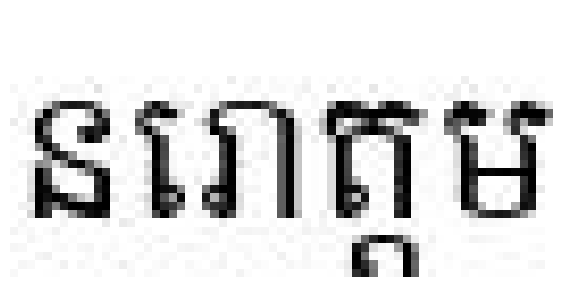

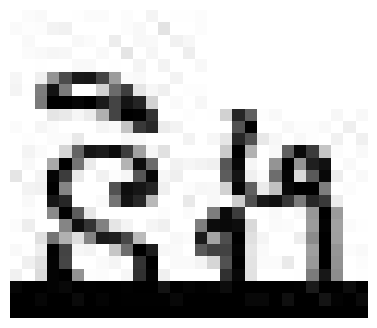

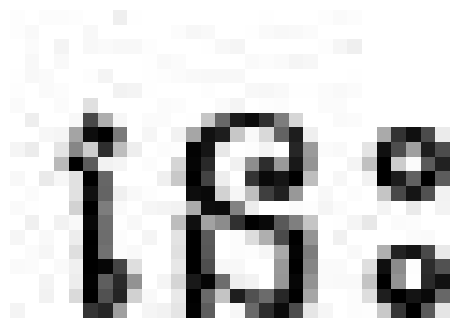

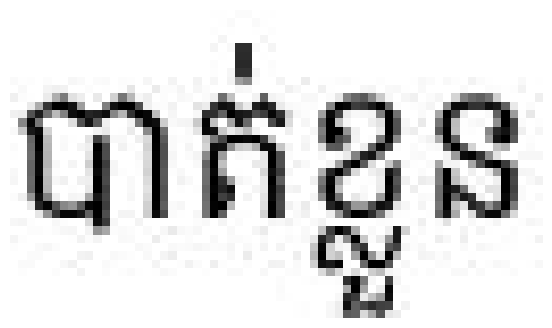

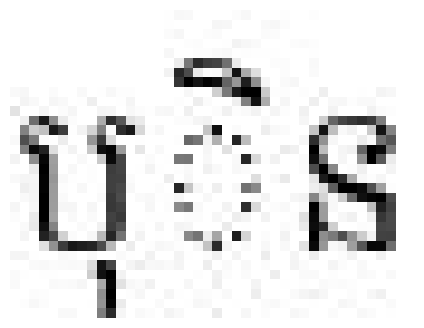

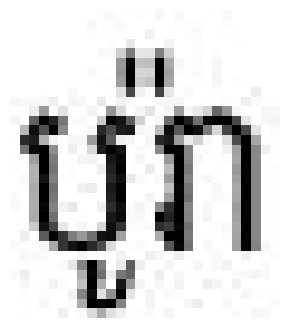

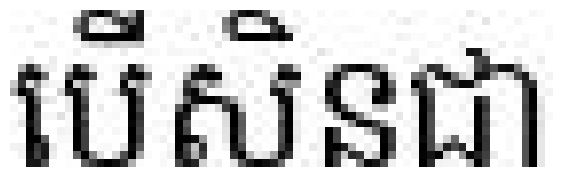

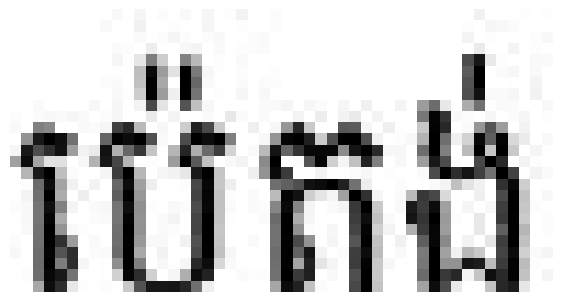

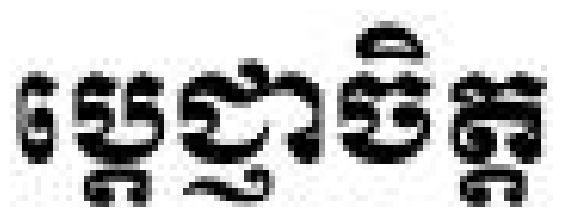

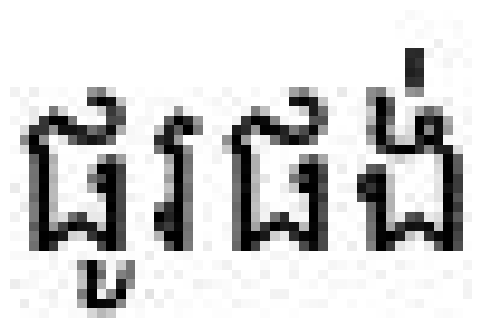

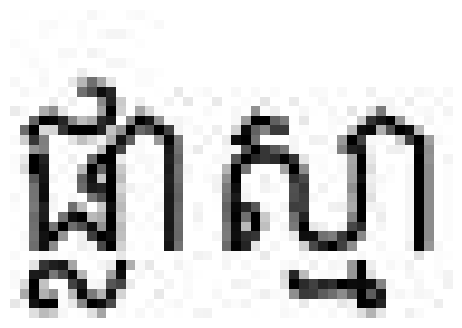

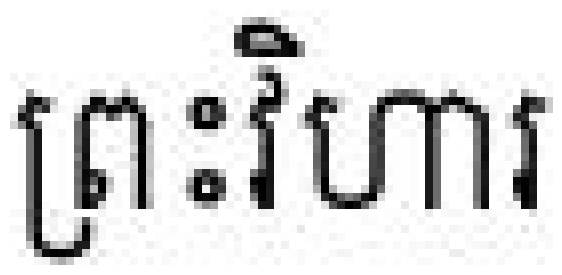

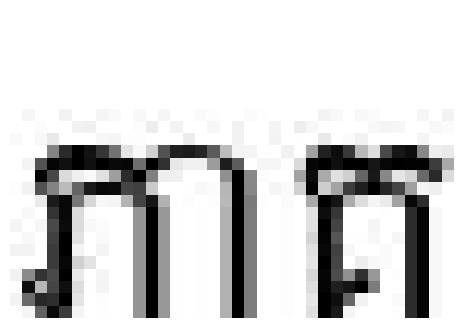

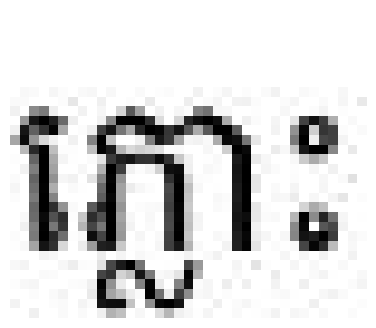

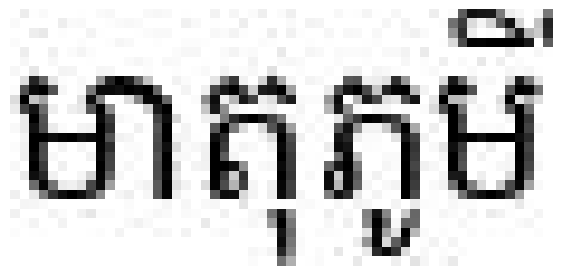

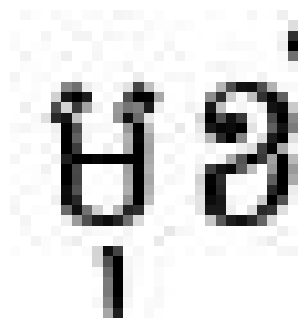

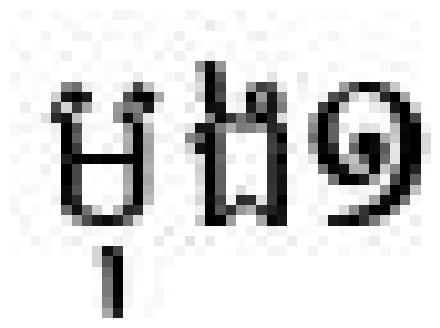

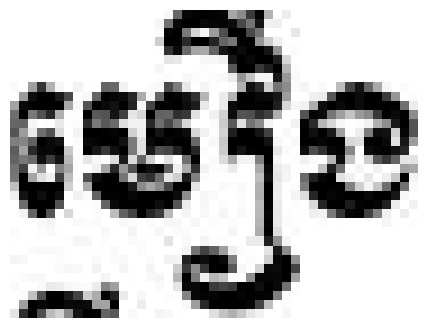

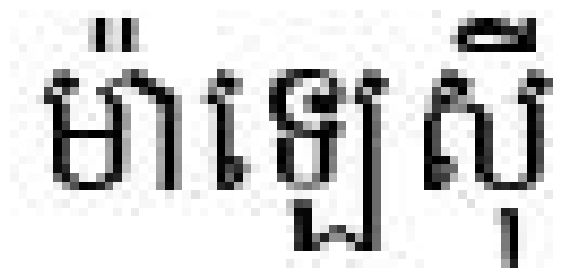

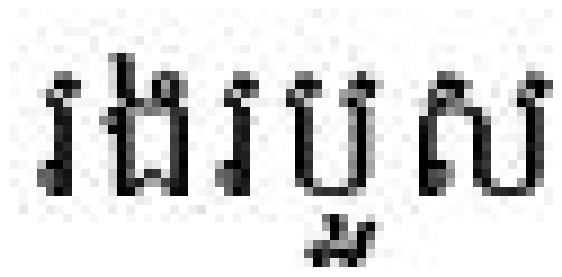

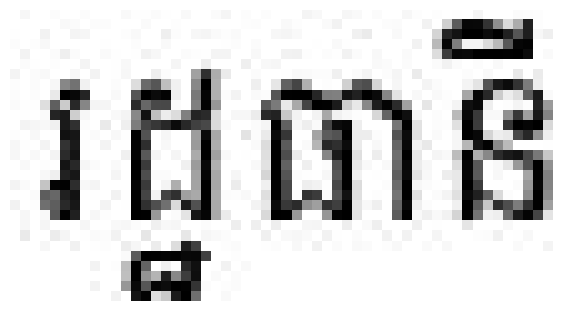

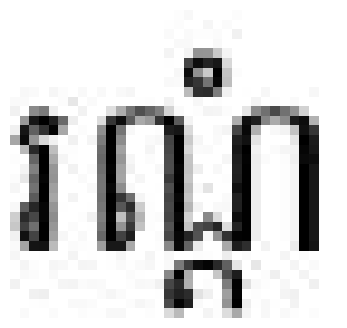

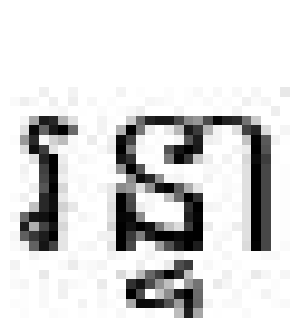

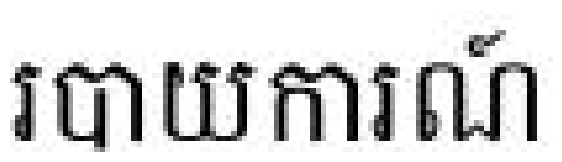

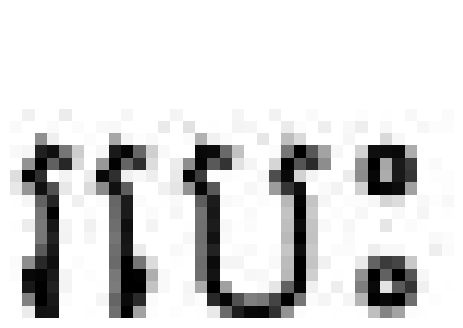

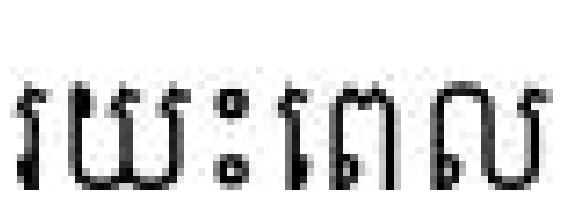

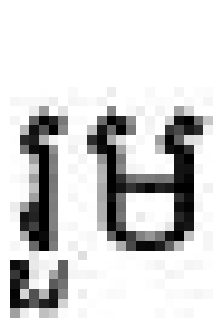

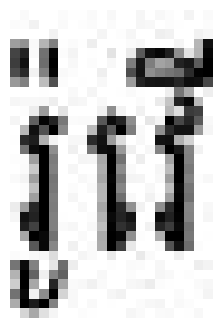

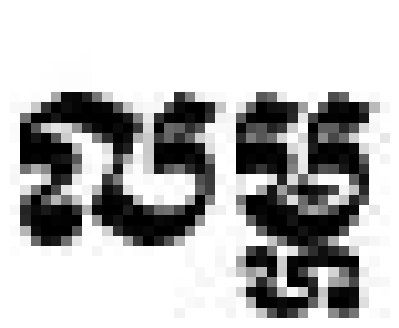

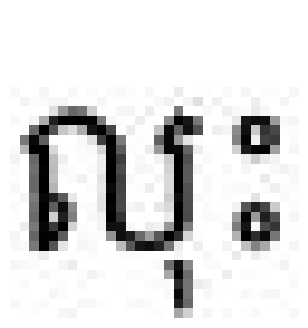

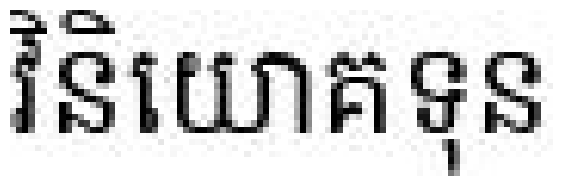

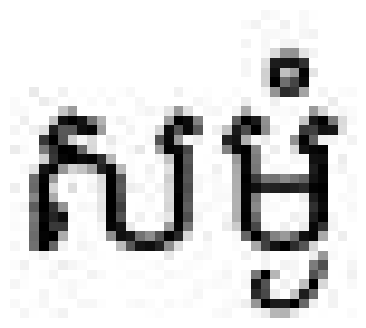

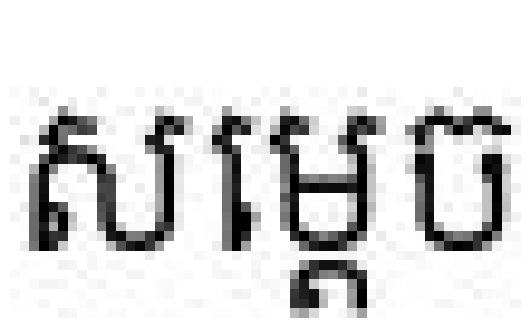

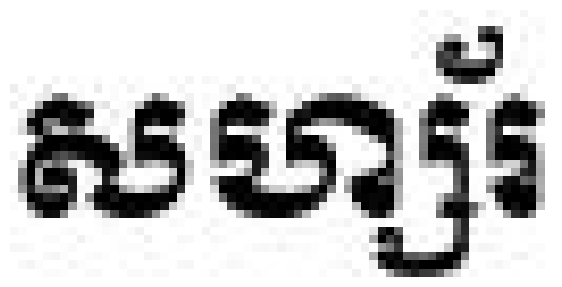

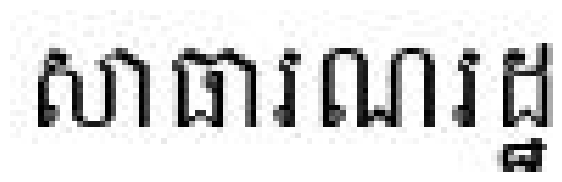

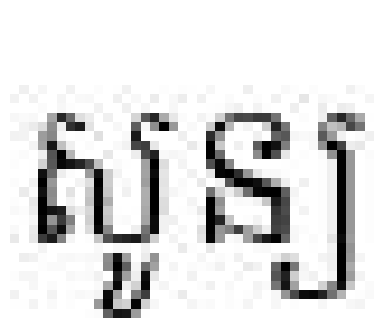

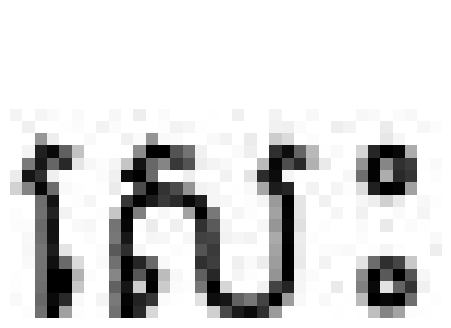

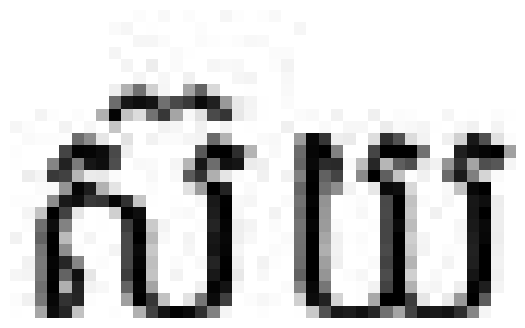

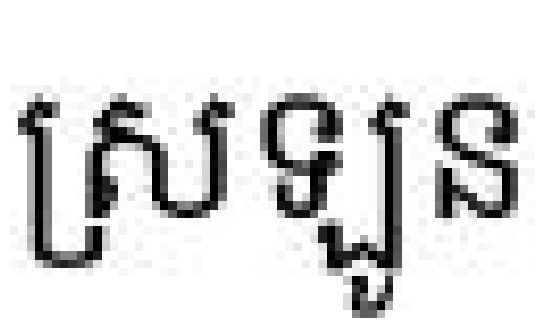

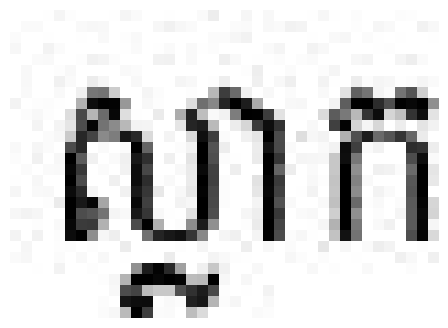

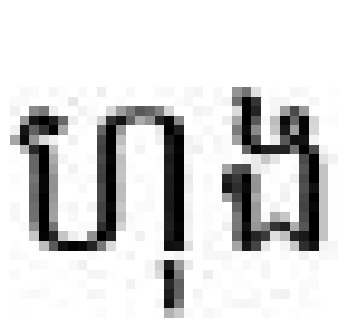

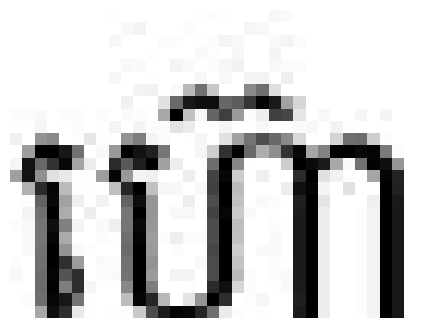

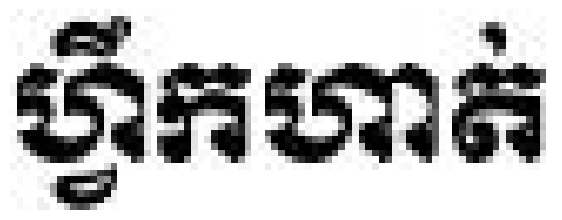

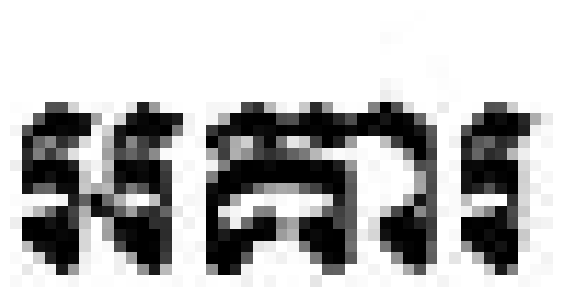

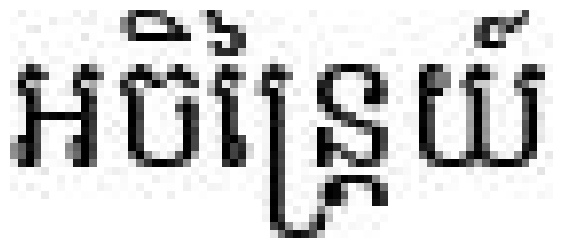

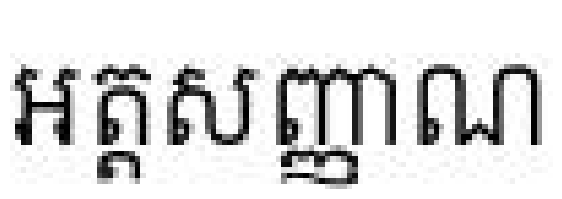

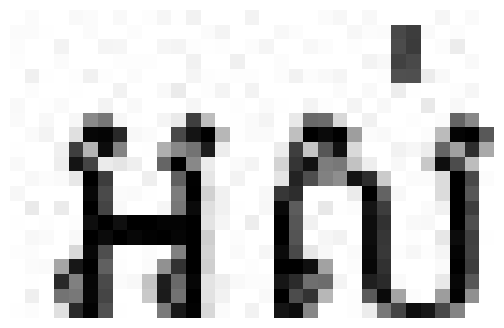

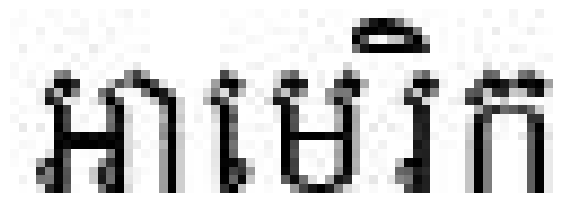

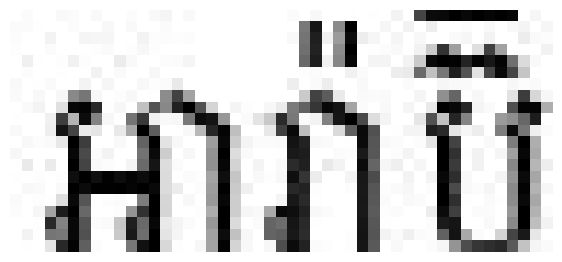

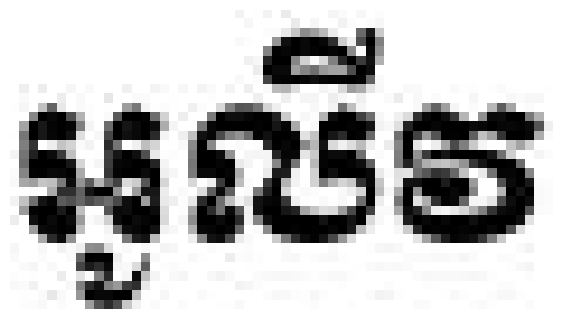

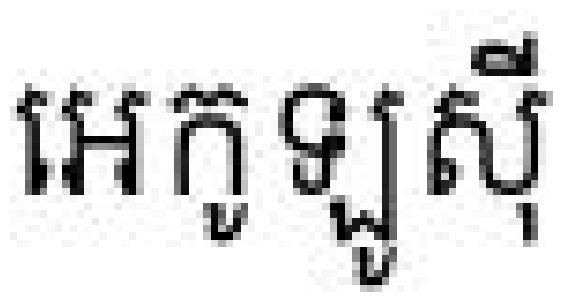

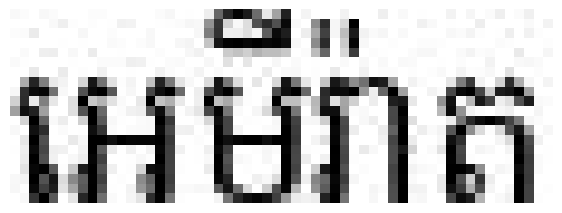

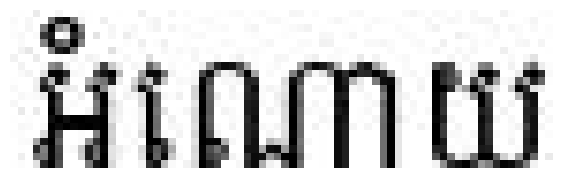

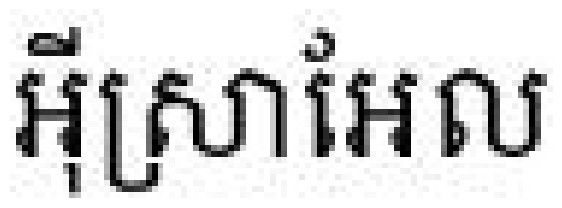

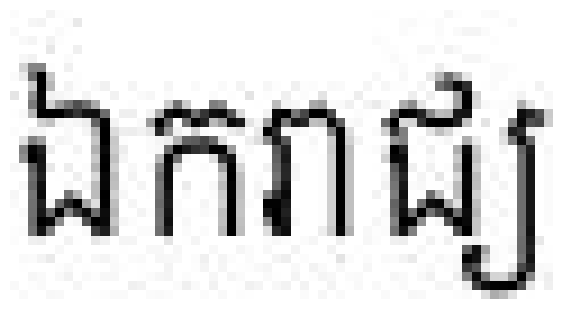

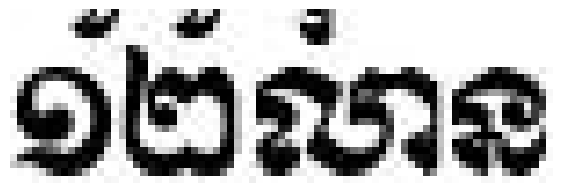

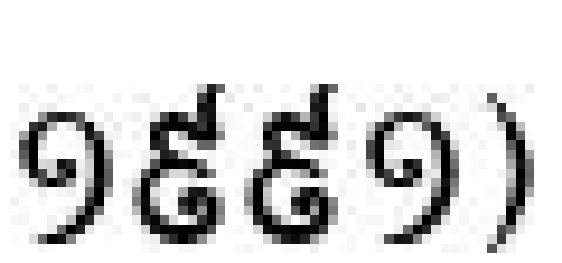

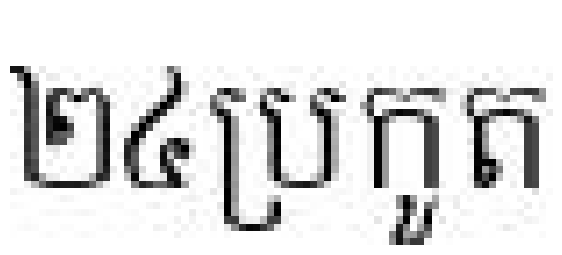

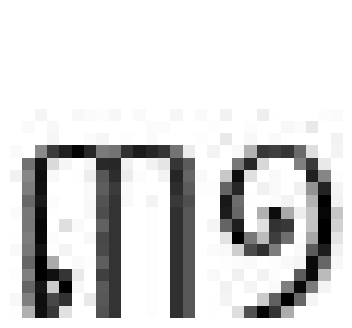

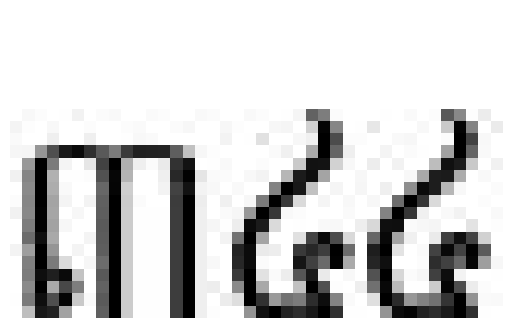

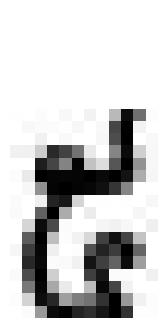

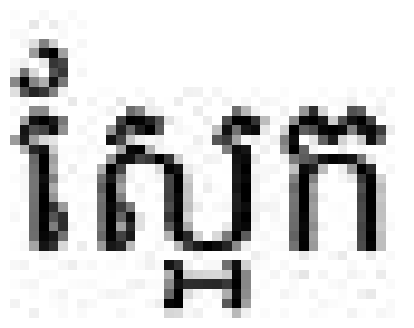

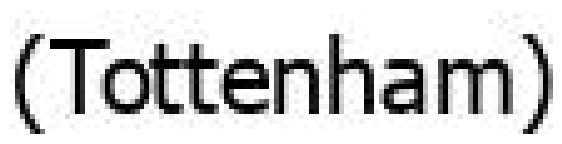

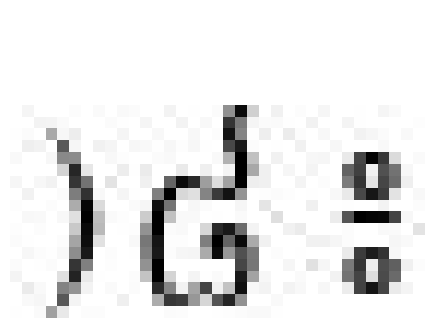

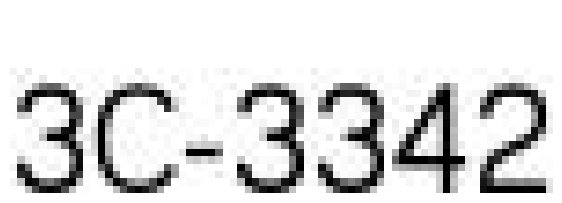

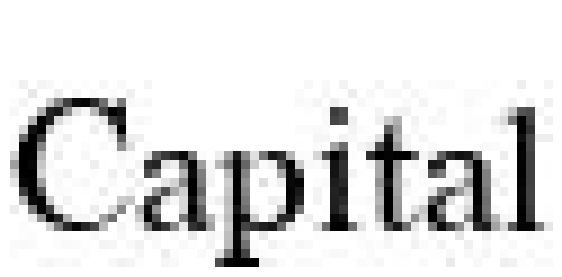

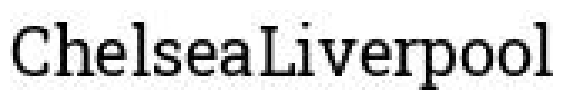

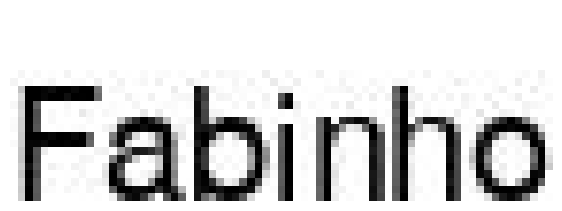

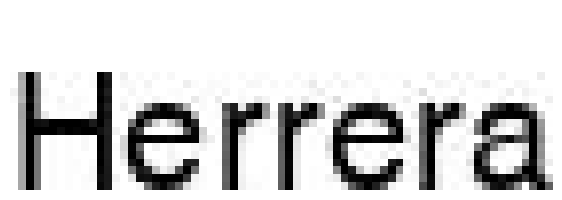

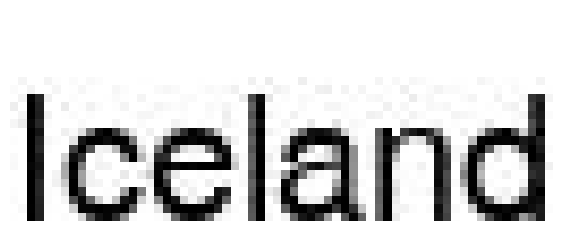

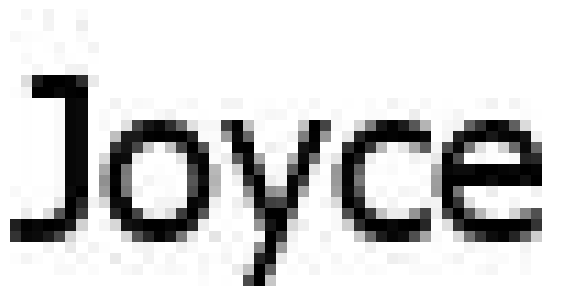

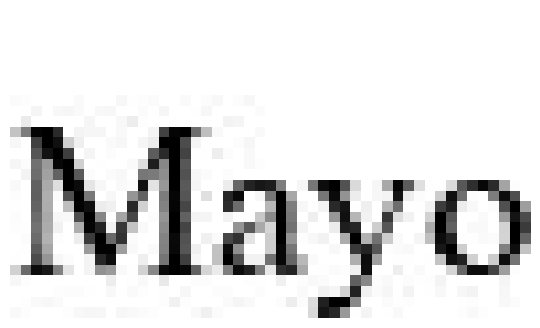

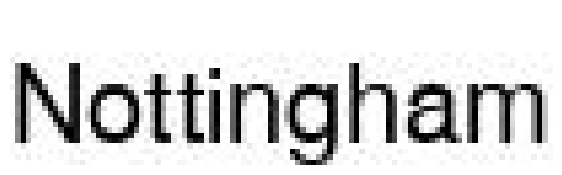

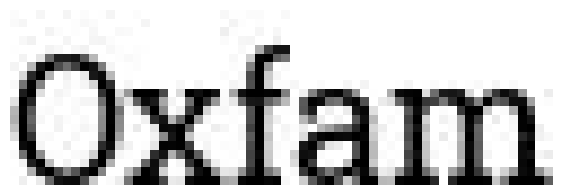

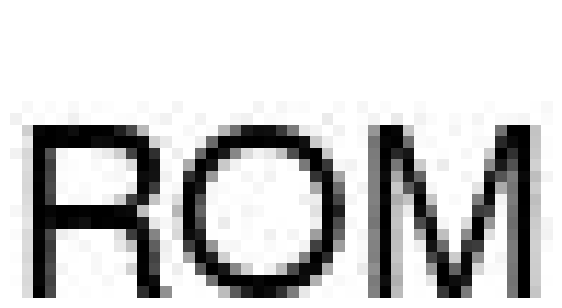

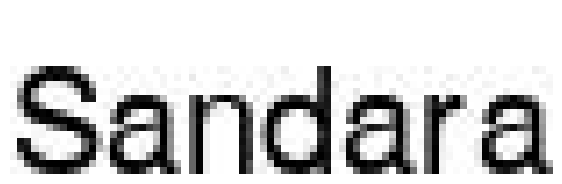

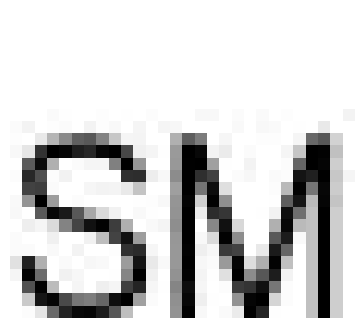

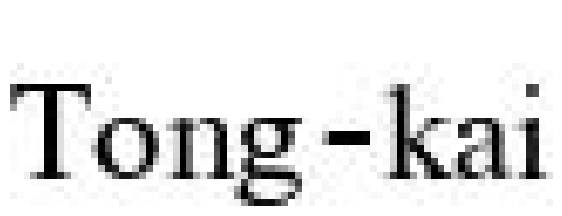

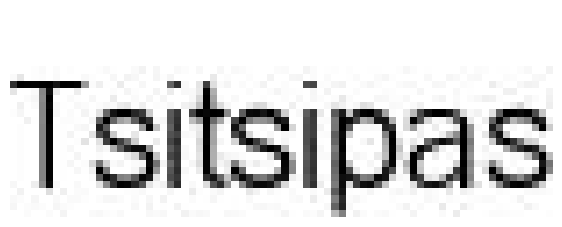

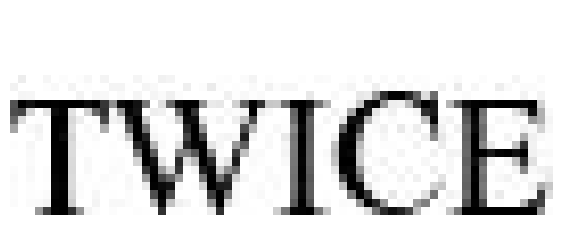

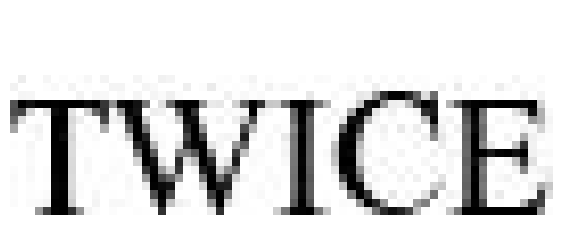

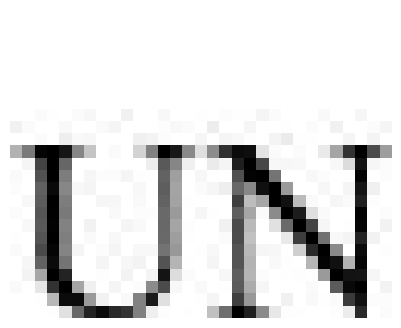

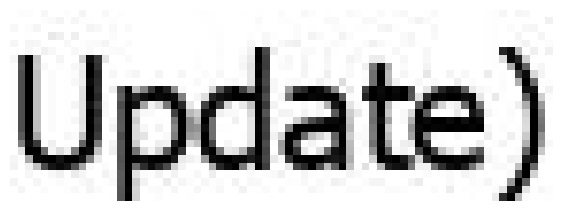

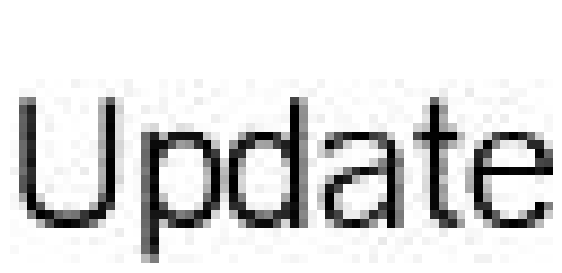

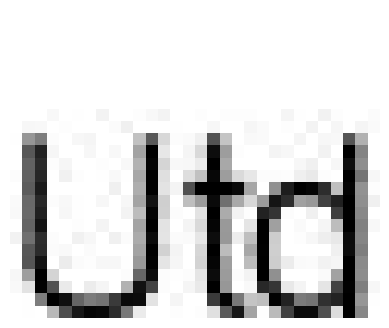

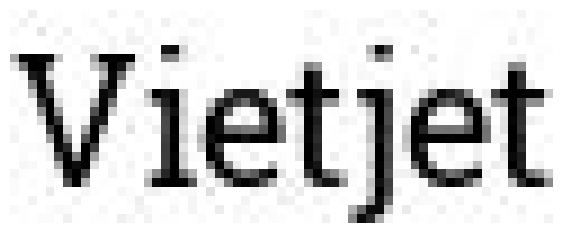

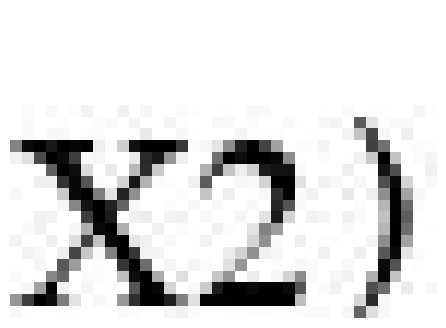

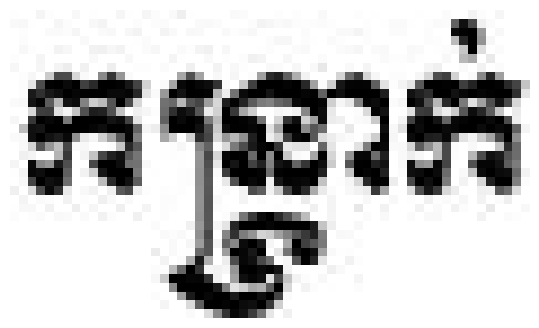

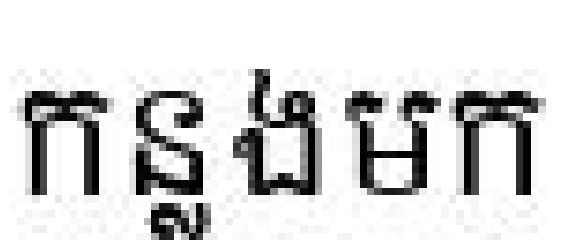

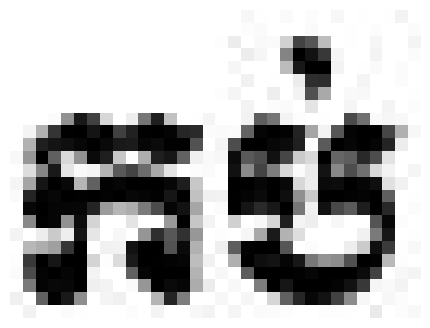

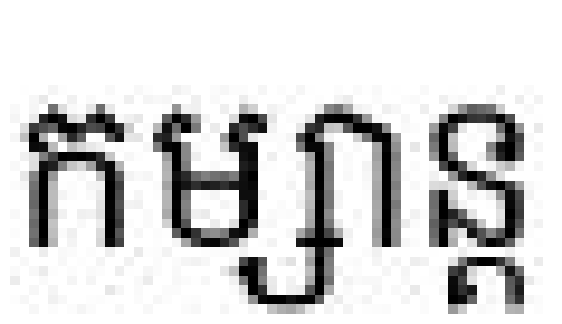

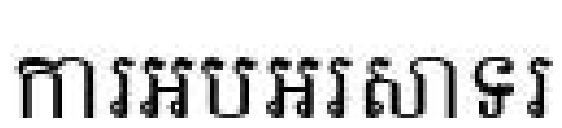

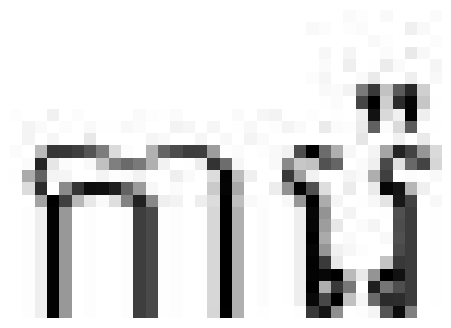

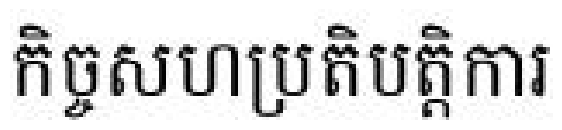

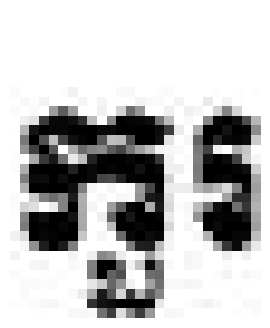

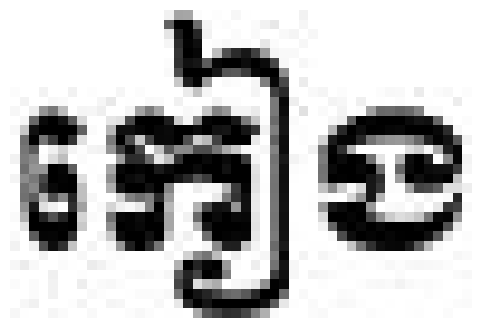

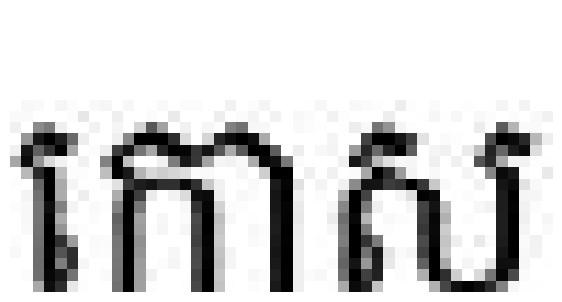

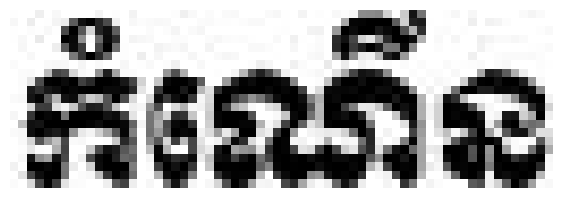

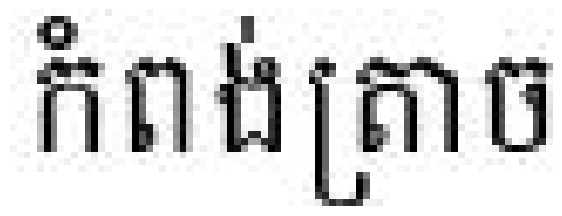

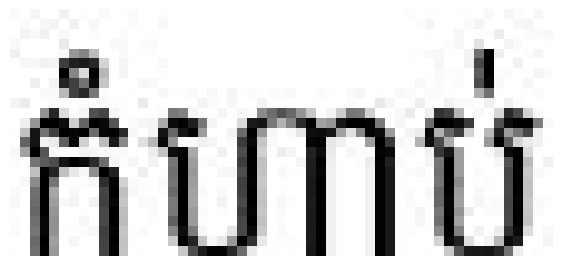

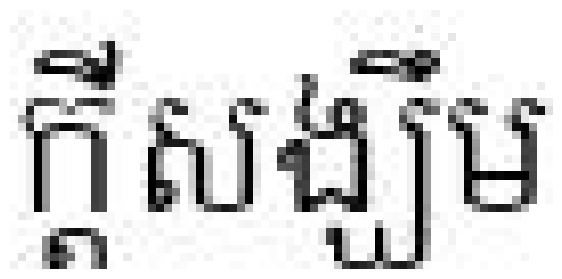

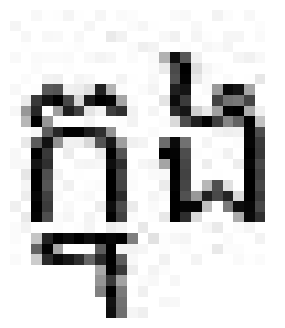

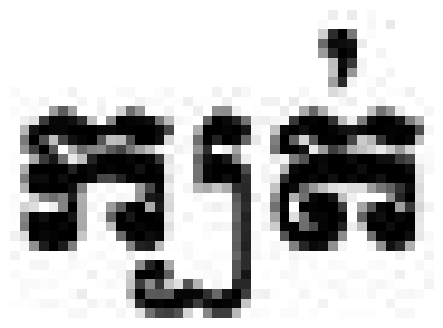

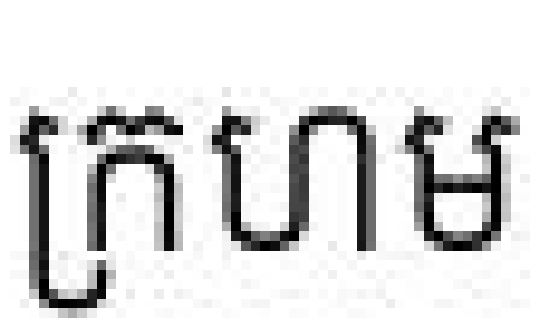

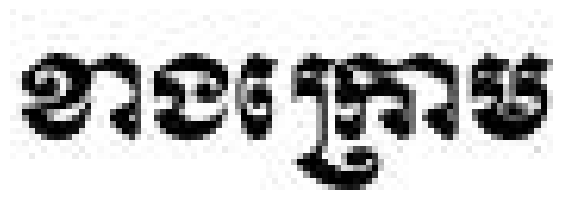

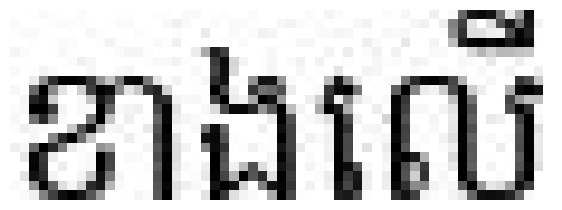

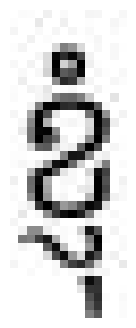

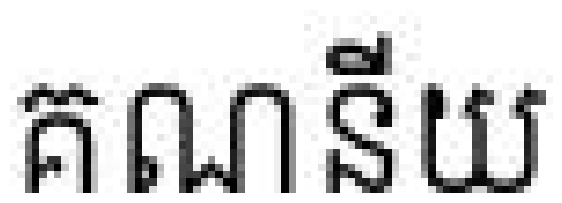

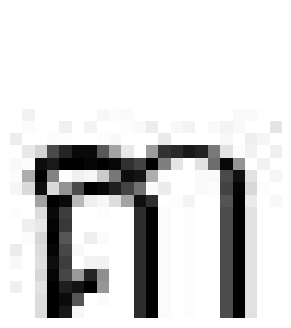

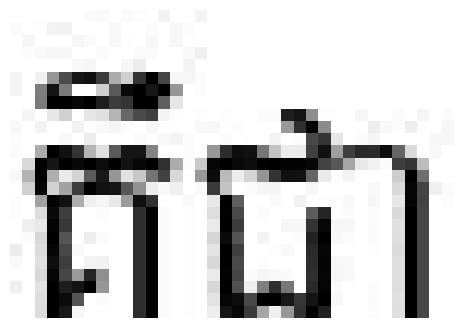

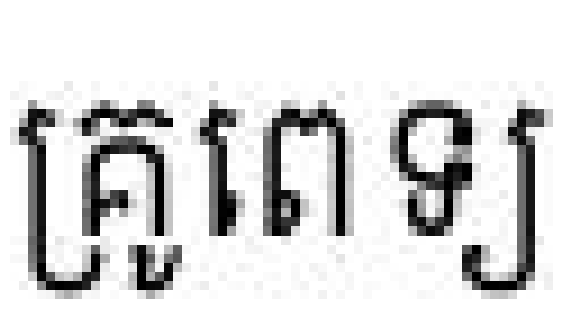

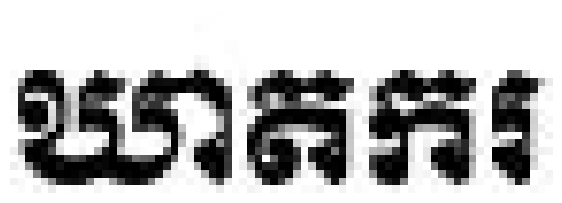

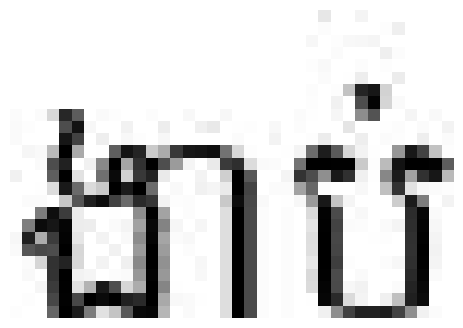

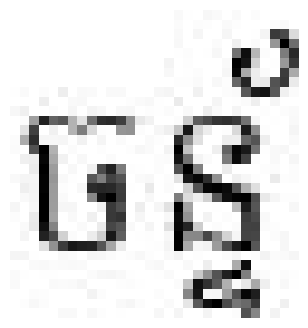

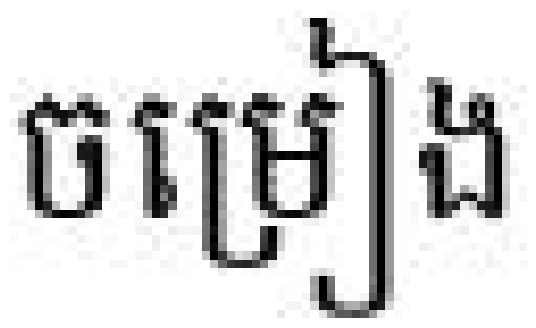

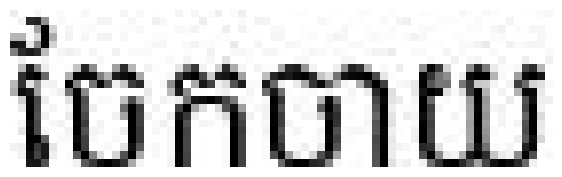

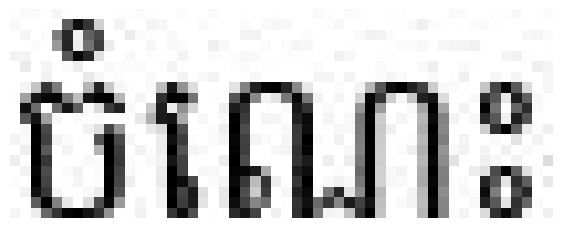

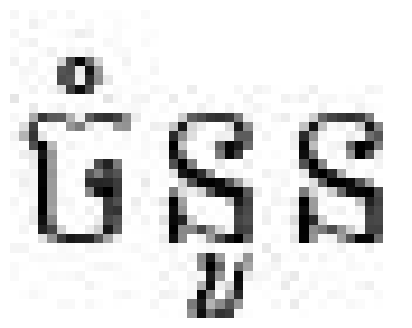

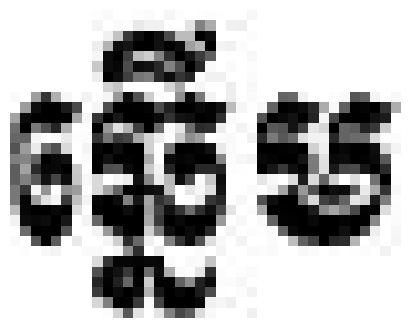

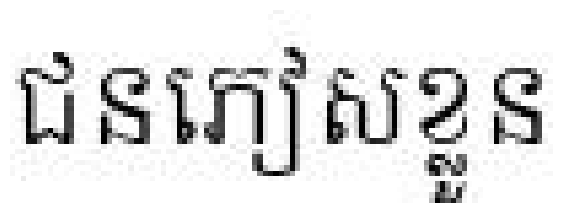

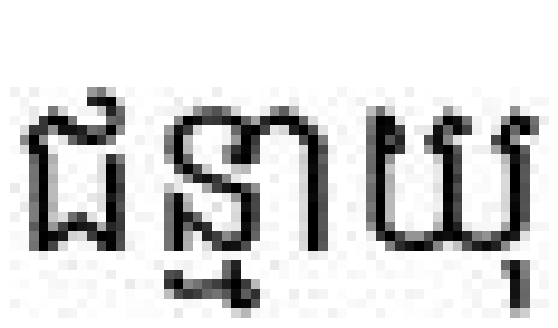

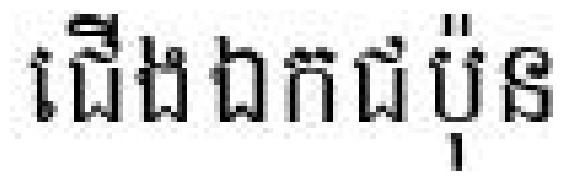

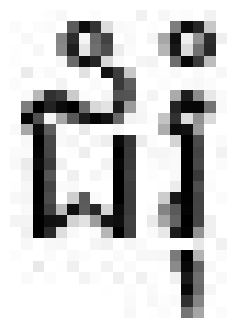

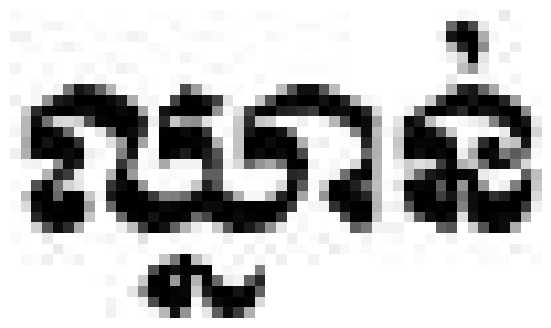

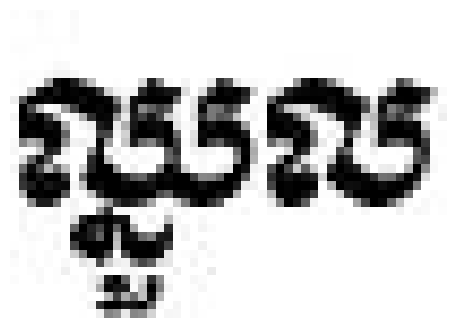

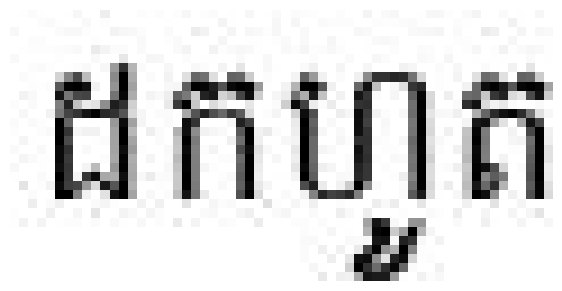

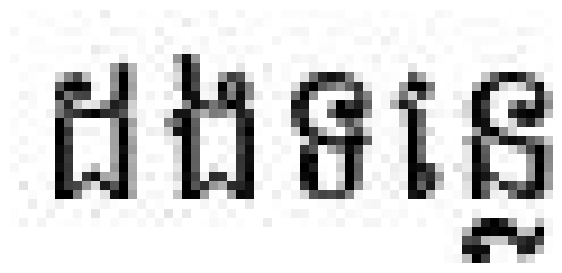

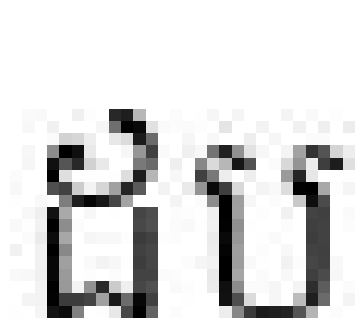

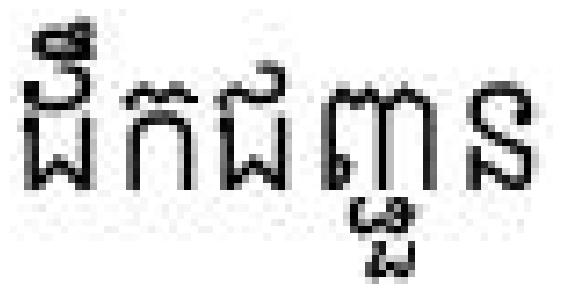

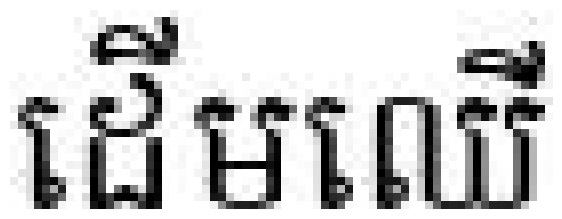

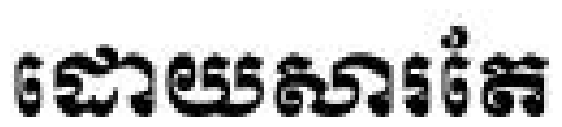

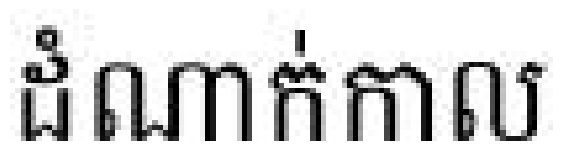

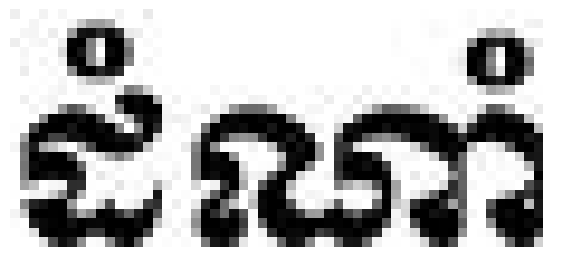

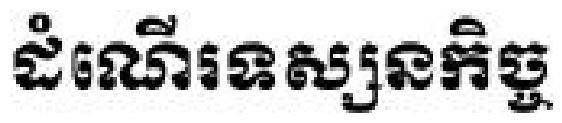

In [82]:
eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_train', '*'),
    num_samples=300
)

In [ ]:
!pip install --upgrade jupyter ipywidgets
